# MSI5001 SER

Compare seven models on AESDD: DummyClassifier, KNN, Logistic Regression, 
Random Forest, SVM, MLP and CNN.

Run sections 1–10 in order. Sections 1–8 establish the baseline;
section 9 tunes each model using training-data validation, and section 10 compares
baseline and optimised predictions on the same outer test recordings. Set `FEATURE_SET` in section 4 to `'rich'`
for 120 acoustic features and log-mel + delta + delta-delta CNN inputs (default),
or `'basic'` for 40 MFCC mean/std features and log-mel-only CNN inputs.
Each CNN channel has 64 mel bands × 128 time bins. Evaluation uses five-fold stratified group random
CV and LOSO by speaker (six folds for AESDD). Alternate takes stay together in
random CV. Each recording is tested once per protocol. Report pooled out-of-fold
accuracy/macro F1 and fold mean ± standard deviation for both protocols.
Baseline and optimised models use identical outer folds.

## 1. Install dependency & import library

Installation is optional when the selected kernel already has the dependencies.
Run installation before imports and restart the kernel after upgrades if required.
For local NVIDIA GPU support, install a CUDA-enabled PyTorch build using the
[official selector](https://pytorch.org/get-started/locally/) in your environment;
skip the installation cell once that environment is ready.

In [1]:
%pip install --upgrade numpy pandas scikit-learn librosa soundfile gdown matplotlib ipython torch

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import re, zipfile, hashlib
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Audio, Markdown
import librosa
import soundfile as sf
import gdown
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedGroupKFold, LeaveOneGroupOut
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

## 2. Load dataset

Choose `local` or `drive`. Local input accepts a WAV directory, ZIP, or folder of ZIPs.
Drive input copies a public folder or dataset ZIP locally without mounting Drive.
The Drive sharing setting must be **Anyone with the link → Viewer**.
This section lists candidate AESDD files; audio validation and cleanup happen in section 3.

In [3]:
SOURCE = 'local'                         # 'local' or 'drive'
LOCAL_PATH = r'./AESDD'                   # WAV directory, ZIP, or folder of ZIPs
DRIVE_URL = 'PASTE_PUBLIC_FILE_OR_FOLDER_URL_HERE'

root = Path(LOCAL_PATH).expanduser().resolve()
if SOURCE == 'drive':
    root = Path('./downloaded_AESDD').resolve()
    root.mkdir(exist_ok=True)
    if '/folders/' in DRIVE_URL:
        downloaded = gdown.download_folder(DRIVE_URL, output=str(root), use_cookies=False)
    else:
        downloaded = gdown.download(DRIVE_URL, output=str(root/'dataset.zip'), use_cookies=False)
    if not downloaded:
        raise RuntimeError('Download failed. Use a public anyone-with-the-link Drive URL.')
elif SOURCE != 'local':
    raise ValueError("SOURCE must be 'local' or 'drive'.")
if not root.exists():
    raise FileNotFoundError(f'Edit LOCAL_PATH: {root}')

def unzip(path):
    destination = path.with_suffix('')
    if not (destination/'.extracted').exists():
        with zipfile.ZipFile(path) as archive:
            if any(not (destination/name).resolve().is_relative_to(destination.resolve())
                   for name in archive.namelist()):
                raise ValueError('Unsafe archive path')
            archive.extractall(destination)
        (destination/'.extracted').touch()
    return destination

if root.is_file():
    root = unzip(root)
for _ in range(3):                       # Also handles ZIPs inside a downloaded folder
    for archive in list(root.rglob('*.zip')):
        unzip(archive)

codes = {'a':'Anger', 'd':'Disgust', 'f':'Fear', 'h':'Happiness', 's':'Sadness'}
pattern = re.compile(r'([adfhs])\s*[_ -]?(\d{1,2})\s*[_ -]?\(\s*(\d+)\s*\)\s*[a-z]*', re.I)
records = []
for path in sorted(root.rglob('*.wav')):
    match = pattern.fullmatch(path.stem)
    if not match or '__MACOSX' in path.parts:
        continue
    emotion, utterance, speaker = match.groups()
    emotion, speaker = emotion.lower(), str(int(speaker))
    records.append({'path':path, 'emotion':codes[emotion], 'speaker':speaker,
                    'group':f'{speaker}_{emotion}_{int(utterance)}'})
if not records:
    raise ValueError('No AESDD WAV filenames found. Check the dataset path and filenames.')
recordings = pd.DataFrame(records)
display(pd.DataFrame([{'Source':SOURCE, 'Dataset folder':str(root),
                       'Candidate recordings':len(recordings)}]))

,Source,Dataset folder,Candidate recordings
0,local,"C:\Users\lichow\Dropbox\NUS\MSI5001 Introduction to AI Concepts, Applications, and Evaluation\Group Project\GitHub\msi5001-ser\AESDD",605


## 3. Explore and clean dataset

Inspect the candidate counts, then remove byte-identical duplicates and skip
damaged, empty, non-finite or silent WAVs. Silence is checked on the mono signal;
the original samples are cached for preprocessing and playback.
Tables show counts before and after cleanup, removal reasons, speaker/emotion
distribution, and the first five usable recordings. Audio players preview those
five recordings. Playback normalization does not alter the model inputs.

**Cleanup summary**

,Recordings
Before cleanup,605
Removed duplicates,0
Skipped invalid WAVs,1
After cleanup,604


**Removed recordings**

,File,Status,Reason
0,s05 (3).wav,Invalid,"Error opening 'C:\\Users\\lichow\\Dropbox\\NUS\\MSI5001 Introduction to AI Concepts, Applications, and Evaluation\\Group Project\\GitHub\\msi5001-ser\\AESDD\\sadness\\s05 (3).wav': Error in WAV file. No 'data' chunk marker."


**Recordings per emotion**

,Before cleanup,After cleanup
emotion,,
Anger,121,121
Disgust,122,122
Fear,120,120
Happiness,119,119
Sadness,123,122


**Usable recordings per speaker and emotion**

emotion,Anger,Disgust,Fear,Happiness,Sadness
speaker,,,,,
1,20,20,20,20,20
2,20,20,20,20,20
3,20,20,20,19,19
4,20,20,19,20,20
5,21,22,21,20,23
6,20,20,20,20,20


**Recording duration (seconds)**

,Seconds
mean,4.10
std,1.62
min,0.98
25%,2.90
50%,3.76
75%,4.86
max,12.73


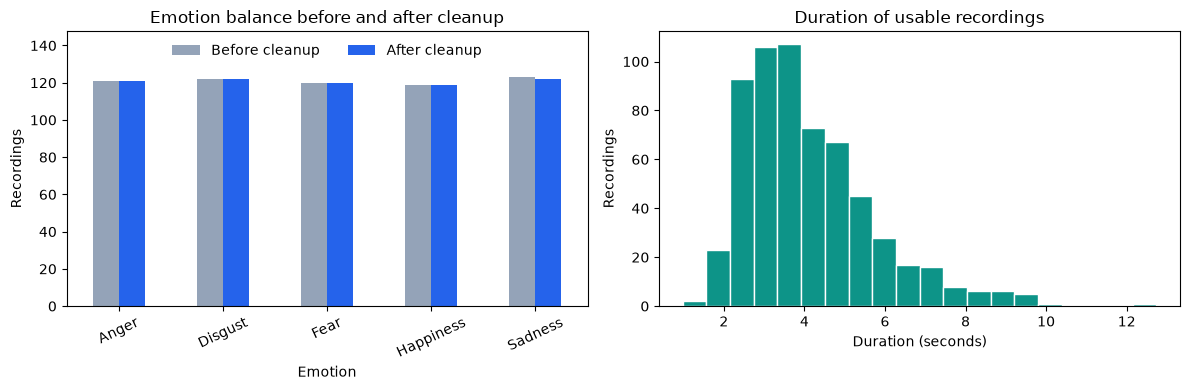

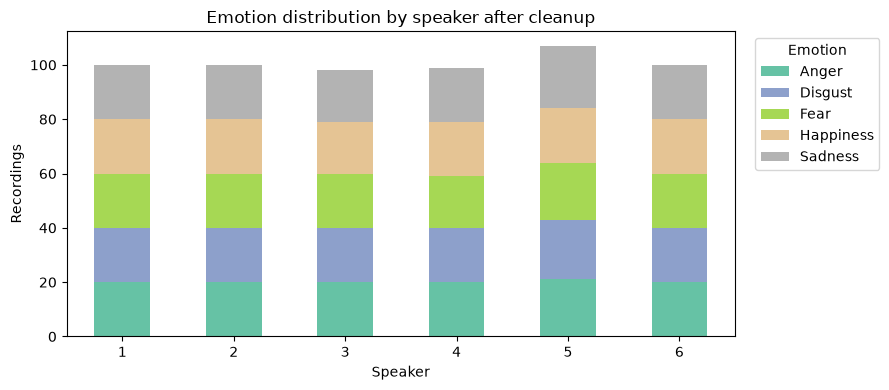

**One random recording per emotion**

,file,emotion,speaker,duration_s,sample_rate,channels
0,a02 (4).wav,Anger,4,4.24,44100,1
1,d19 (6).wav,Disgust,6,6.38,44100,1
2,f05 (1).wav,Fear,1,2.34,44100,1
3,h20 (4).wav,Happiness,4,2.60,44100,1
4,s17 (4).wav,Sadness,4,4.46,44100,1


**1. a02 (4).wav** — Anger, speaker 4

**2. d19 (6).wav** — Disgust, speaker 6

**3. f05 (1).wav** — Fear, speaker 1

**4. h20 (4).wav** — Happiness, speaker 4

**5. s17 (4).wav** — Sadness, speaker 4

In [4]:
before_counts = recordings.emotion.value_counts().sort_index()
candidate_count = len(recordings)
clean_records, cleanup_log, audio_cache, seen = [], [], {}, set()
for record in recordings.to_dict('records'):
    path = record['path']
    try:
        digest = hashlib.sha256(path.read_bytes()).hexdigest()
        if digest in seen:
            cleanup_log.append({'File':path.name, 'Status':'Duplicate',
                                'Reason':'Byte-identical to a retained recording'})
            continue
        audio, sr = sf.read(path, dtype='float32', always_2d=True)
        if not len(audio) or sr <= 0:
            raise ValueError('Empty recording or invalid sample rate')
        if not np.isfinite(audio).all():
            raise ValueError('Non-finite audio samples')
        if np.max(np.abs(audio.mean(axis=1))) < 1e-7:
            raise ValueError('Silent mono signal')
    except (RuntimeError, ValueError, OSError) as error:
        cleanup_log.append({'File':path.name, 'Status':'Invalid', 'Reason':str(error)})
        continue
    clean_records.append({**record, 'duration_s':len(audio)/sr,
                          'sample_rate':sr, 'channels':audio.shape[1]})
    audio_cache[path] = (audio, sr)
    seen.add(digest)
if not clean_records:
    raise ValueError('No usable recordings remain after cleanup.')
recordings = pd.DataFrame(clean_records)
cleanup_log = pd.DataFrame(cleanup_log, columns=['File', 'Status', 'Reason'])
cleanup_summary = pd.DataFrame({
    'Recordings':[candidate_count, (cleanup_log.Status == 'Duplicate').sum(),
                  (cleanup_log.Status == 'Invalid').sum(), len(recordings)]
}, index=['Before cleanup', 'Removed duplicates', 'Skipped invalid WAVs', 'After cleanup'])
display(Markdown('**Cleanup summary**'))
display(cleanup_summary)
if not cleanup_log.empty:
    display(Markdown('**Removed recordings**'))
    display(cleanup_log)

emotion_counts = pd.DataFrame({'Before cleanup':before_counts,
                               'After cleanup':recordings.emotion.value_counts()}).fillna(0).astype(int)
emotion_counts = emotion_counts.sort_index()
speaker_counts = pd.crosstab(recordings.speaker, recordings.emotion)
display(Markdown('**Recordings per emotion**'))
display(emotion_counts)
display(Markdown('**Usable recordings per speaker and emotion**'))
display(speaker_counts)
display(Markdown('**Recording duration (seconds)**'))
display(recordings.duration_s.describe().drop('count').to_frame('Seconds').round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
emotion_counts.plot.bar(ax=axes[0], color=['#94a3b8', '#2563eb'], rot=25)
axes[0].set(title='Emotion balance before and after cleanup', xlabel='Emotion', ylabel='Recordings')
axes[0].set_ylim(0, emotion_counts.to_numpy().max()*1.2)
axes[0].legend(loc='upper center', ncol=2, frameon=False)
recordings.duration_s.plot.hist(ax=axes[1], bins=20, color='#0d9488', edgecolor='white')
axes[1].set(title='Duration of usable recordings', xlabel='Duration (seconds)', ylabel='Recordings')
fig.tight_layout()
plt.show()

ax = speaker_counts.plot.bar(stacked=True, figsize=(9, 4), colormap='Set2', rot=0)
ax.set(title='Emotion distribution by speaker after cleanup', xlabel='Speaker', ylabel='Recordings')
ax.legend(title='Emotion', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.figure.tight_layout()
plt.show()

emotion_samples = (
    recordings.groupby('emotion')
    .sample(n=1)
    .sort_values('emotion')
    .copy()
)

emotion_samples['file'] = emotion_samples.path.map(lambda path: path.name)

display(Markdown('**One random recording per emotion**'))
display(
    emotion_samples[['file', 'emotion', 'speaker', 'duration_s', 'sample_rate', 'channels']]
    .reset_index(drop=True)
    .round({'duration_s': 2})
)

for i, record in enumerate(emotion_samples.itertuples(index=False), start=1):
    display(Markdown(
        f'**{i}. {record.path.name}** — {record.emotion}, speaker {record.speaker}'
    ))
    audio, sr = audio_cache[record.path]
    display(Audio(data=audio.T, rate=sr))


## 4. Data preprocessing

Convert to mono and resample to 16 kHz. One selector controls both model inputs:

| `FEATURE_SET` | Feature-vector models (including MLP) | CNN input per recording |
| --- | --- | --- |
| `'basic'` | 40 MFCC mean/std features | Log-mel only: **1 × 64 × 128** |
| `'rich'` (default) | 120 acoustic features | Log-mel + delta + delta-delta: **3 × 64 × 128** |

The rich acoustic features retain the following category order:

| Category | Feature | Summary statistics | Count |
| --- | --- | --- | ---: |
| Cepstral | MFCC | Mean/std of 20 coefficients | 40 |
| | Delta MFCC | Std of 20 first-order delta coefficients | 20 |
| Spectral | Centroid | Mean/std | 2 |
| | Bandwidth | Mean/std | 2 |
| | 85% roll-off | Mean/std | 2 |
| | Flatness | Mean/std | 2 |
| | Contrast | Mean/std across 7 frequency bands | 14 |
| Prosodic | Pitch (F0) | Mean, std, P5, P95; P5–P95 range in semitones | 5 |
| | Energy | Active-frame RMS dBFS mean, std, P5, P95 | 4 |
| | Timing and voicing | Pause ratio, pauses per second, voiced-frame ratio | 3 |
| Harmonic | Chroma | Mean/std across 12 pitch classes | 24 |
| Time-domain | Zero-crossing rate | Mean/std | 2 |
| **Total** | | | **120** |

MFCCs describe the spectral envelope. First-order delta MFCCs use a 9-frame window
with nearest-edge padding; retain each coefficient's standard deviation.
Spectral contrast uses `n_bands=6`, returning 7 bands. Flatness describes noise-like
versus tonal spectral structure. These summaries include the whole recording.

Pitch uses pYIN over a fixed 50–600 Hz range. Only finite, voiced estimates
contribute; all five pitch statistics are zero when none are detected.
The semitone range is `12 * log2(P95 / P5)`.

Energy/timing use 25 ms RMS windows with a 10 ms hop. A low-energy frame is more
than 30 dB below that clip's maximum frame RMS level. Internal low-energy runs
lasting at least 150 ms count as pause proxies; leading/trailing silence is excluded.
Pause duration and count are divided by the full clip duration. Energy statistics
use active frames. Voiced ratio is the fraction of pYIN frames flagged as voiced.
RMS dBFS is a digital level, not calibrated physical loudness. Equal peak levels
do not imply equal RMS levels. These rules are fixed per recording.

Chroma uses `librosa.feature.chroma_stft` with 12 pitch classes and its default
per-frame normalisation and fixed A440 reference (`tuning=0.0`). This bypasses
automatic tuning estimation, which triggered a Numba cast warning. Each pitch class contributes its
mean and standard deviation across the whole recording. Chroma combines octaves;
F0 separately retains pitch height. No individual feature determines an emotion.

Compared with the previous 97-feature rich set, add 24 chroma summaries and remove
clip duration from model inputs: **97 + 24 - 1 = 120**. Duration remains in metadata
and pause calculations; it also depends on the length of the spoken content.
Jitter/shimmer and onset rate remain omitted, as do extra energy-range statistics.

CNN rich channels are log-mel, its first-order temporal derivative (delta), and
its second-order temporal derivative (delta-delta), in that order. Derivatives use
`librosa.feature.delta` with a 9-frame window and nearest-edge padding along time.
Calculate both on the original log-mel matrix **before** resizing all channels
together to 64×128. These are log-mel derivatives, separate from the delta MFCC
summary features used by the feature-vector models. No MFCC sequence enters the CNN.

Re-run sections **4–10** after changing `FEATURE_SET` or feature definitions. Basic
mode skips the other acoustic feature families. Baseline and tuned models use the
same selected inputs. Learned scaling stays in sections 6 and 9; no dataset-wide
statistics are fitted during extraction.

,Input,Shape,Used by
0,Acoustic features (rich),"(604, 120)",Five scikit-learn models + PyTorch MLP
1,Log-mel + Delta + Delta-delta,"(604, 3, 64, 128)",CNN
2,Emotion labels,"(604,)",All seven models


,Label,Emotion
0,0,Anger
1,1,Disgust
2,2,Fear
3,3,Happiness
4,4,Sadness


,Category,Feature,Statistics,Feature count
0,Cepstral,MFCC,Mean/std of 20 coefficients,40
1,Cepstral,Delta MFCC,Std of 20 first-order delta coefficients,20
2,Spectral,Spectral centroid,Mean/std,2
3,Spectral,Spectral bandwidth,Mean/std,2
4,Spectral,Spectral roll-off,Mean/std; 85% energy threshold,2
5,Spectral,Spectral flatness,Mean/std,2
6,Spectral,Spectral contrast,Mean/std of 7 bands,14
7,Prosodic,Pitch,Mean/std/P5/P95; semitone range,5
8,Prosodic,Energy,Active-frame RMS dBFS mean/std/P5/P95,4
9,Prosodic,Timing and voicing,Pause ratio/pause rate/voiced ratio,3


,Category,Feature count
0,Cepstral,60
1,Spectral,22
2,Prosodic,12
3,Harmonic,24
4,Time-domain,2


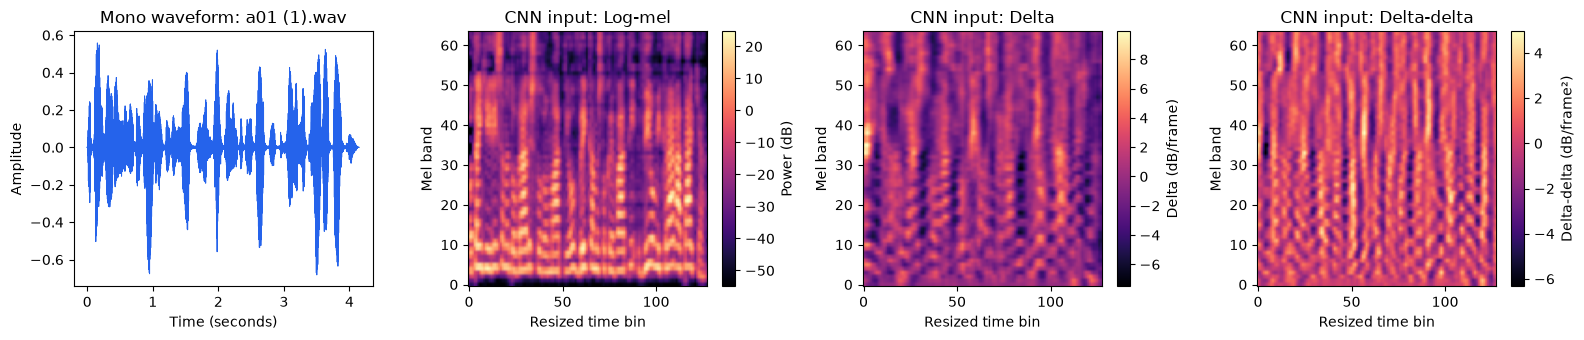

In [7]:
FEATURE_SET = 'rich'  # 'basic': 40 MFCC + log-mel; 'rich': 120 features + log-mel/delta/delta-delta
if FEATURE_SET not in {'basic', 'rich'}:
    raise ValueError("FEATURE_SET must be 'basic' or 'rich'.")
CNN_CHANNEL_NAMES = ['Log-mel'] if FEATURE_SET == 'basic' else ['Log-mel', 'Delta', 'Delta-delta']
CNN_INPUT_NAME = ' + '.join(CNN_CHANNEL_NAMES)
feature_names = [f'mfcc_{i:02d}_{stat}' for stat in ['mean', 'std'] for i in range(20)]
if FEATURE_SET == 'rich':
    # Cepstral, Spectral, Prosodic, Harmonic, Time-domain.
    feature_names += [f'delta_mfcc_{i:02d}_std' for i in range(20)]
    feature_names += [f'{name}_{stat}' for name in
                      ['spectral_centroid_hz', 'spectral_bandwidth_hz', 'spectral_rolloff_hz',
                       'spectral_flatness'] for stat in ['mean', 'std']]
    feature_names += [f'spectral_contrast_band_{band}_{stat}' for band in range(7)
                      for stat in ['mean', 'std']]
    feature_names += [f'pitch_hz_{stat}' for stat in ['mean', 'std', 'p05', 'p95']]
    feature_names += ['pitch_range_semitones']
    feature_names += [f'rms_dbfs_{stat}' for stat in ['mean', 'std', 'p05', 'p95']]
    feature_names += ['pause_ratio', 'pauses_per_second', 'voiced_ratio']
    feature_names += [f'chroma_{pitch_class}_{stat}' for pitch_class in
                      ['C', 'C_sharp', 'D', 'D_sharp', 'E', 'F', 'F_sharp', 'G', 'G_sharp', 'A', 'A_sharp', 'B']
                      for stat in ['mean', 'std']]
    feature_names += ['zcr_mean', 'zcr_std']

def extract_ml_features(audio, feature_set=FEATURE_SET):
    mfcc = librosa.feature.mfcc(y=audio, sr=16000, n_mfcc=20)
    values = np.r_[mfcc.mean(axis=1), mfcc.std(axis=1)]
    if feature_set == 'basic':
        return values
    f0, voiced, _ = librosa.pyin(audio, fmin=50, fmax=600, sr=16000)
    pitch = f0[voiced & np.isfinite(f0)]
    pitch_stats = np.zeros(5)
    if pitch.size:
        p05, p95 = np.percentile(pitch, [5, 95])
        pitch_stats = [pitch.mean(), pitch.std(), p05, p95, 12*np.log2(p95/p05)]

    # Active-frame RMS statistics and explicitly defined low-energy pause proxies.
    rms = librosa.feature.rms(y=audio, frame_length=400, hop_length=160)[0]
    rms_db = 20*np.log10(np.maximum(rms, 1e-8))
    active = rms_db >= rms_db.max()-30
    levels = rms_db[active]
    energy_stats = np.r_[levels.mean(), levels.std(), np.percentile(levels, [5,95])]
    internal_silence = ~active
    active_frames = np.flatnonzero(active)
    internal_silence[:active_frames[0]] = False
    internal_silence[active_frames[-1]+1:] = False
    edges = np.diff(np.r_[0, internal_silence.astype(int), 0])
    starts, ends = np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)
    duration = len(audio)/16000
    pause_lengths = np.minimum(ends*0.01, duration)-np.minimum(starts*0.01, duration)
    pause_lengths = pause_lengths[pause_lengths >= 0.15]

    spectral_tracks = [
        librosa.feature.spectral_centroid(y=audio, sr=16000)[0],
        librosa.feature.spectral_bandwidth(y=audio, sr=16000)[0],
        librosa.feature.spectral_rolloff(y=audio, sr=16000, roll_percent=0.85)[0]
    ]
    spectral_stats = np.array([(track.mean(), track.std()) for track in spectral_tracks]).ravel()
    timing = [pause_lengths.sum()/duration, len(pause_lengths)/duration, voiced.mean()]
    zcr = librosa.feature.zero_crossing_rate(audio)[0]
    flatness = librosa.feature.spectral_flatness(y=audio)[0]
    delta_mfcc = librosa.feature.delta(mfcc, width=9, order=1, mode='nearest')
    contrast = librosa.feature.spectral_contrast(y=audio, sr=16000, n_bands=6)
    contrast_stats = np.array([(band.mean(), band.std()) for band in contrast]).ravel()
    chroma = librosa.feature.chroma_stft(y=audio, sr=16000, n_chroma=12, tuning=0.0)
    chroma_stats = np.array([(track.mean(), track.std()) for track in chroma]).ravel()
    return np.r_[values, delta_mfcc.std(axis=1),
                 spectral_stats, flatness.mean(), flatness.std(), contrast_stats,
                 pitch_stats, energy_stats, timing, chroma_stats, zcr.mean(), zcr.std()]

def extract_cnn_features(audio, feature_set=FEATURE_SET):
    if feature_set not in {'basic', 'rich'}:
        raise ValueError("feature_set must be 'basic' or 'rich'.")
    mel = librosa.feature.melspectrogram(y=audio, sr=16000, n_mels=64)
    log_mel = librosa.power_to_db(mel)
    channels = [log_mel]
    if feature_set == 'rich':
        # Differentiate along original time frames, before resizing.
        channels += [librosa.feature.delta(log_mel, width=9, order=order,
                     axis=-1, mode='nearest') for order in [1, 2]]
    tensor = torch.as_tensor(np.stack(channels), dtype=torch.float32)[None]
    return nn.functional.interpolate(tensor, size=(64,128), mode='bilinear',
                                     align_corners=False)[0].numpy()

def cnn_normalisation(train_images):
    # One mean/std per channel, using training clips, mel bands and time bins.
    axes = (0, 2, 3)
    mean = train_images.mean(axis=axes, keepdims=True)
    std = np.maximum(train_images.std(axis=axes, keepdims=True), 1e-8)
    return mean, std

features, images = [], []
for record in recordings.to_dict('records'):
    audio, sr = audio_cache[record['path']]
    audio = librosa.resample(audio.mean(axis=1), orig_sr=sr, target_sr=16000)
    image = extract_cnn_features(audio)
    if not features:
        example_audio = audio
    features.append(extract_ml_features(audio))
    images.append(image)
metadata = recordings.copy()
X, Z = np.asarray(features), np.asarray(images)
if X.shape[1] != len(feature_names) or not np.isfinite(X).all():
    raise ValueError('Acoustic feature count mismatch or non-finite values found.')
if Z.shape[1:] != (len(CNN_CHANNEL_NAMES),64,128) or not np.isfinite(Z).all():
    raise ValueError('CNN input shape mismatch or non-finite values found.')
encoder = LabelEncoder()
y = encoder.fit_transform(metadata.emotion)
display(pd.DataFrame([
    {'Input':f'Acoustic features ({FEATURE_SET})', 'Shape':str(X.shape), 'Used by':'Five scikit-learn models + PyTorch MLP'},
    {'Input':CNN_INPUT_NAME, 'Shape':str(Z.shape), 'Used by':'CNN'},
    {'Input':'Emotion labels', 'Shape':str(y.shape), 'Used by':'All seven models'}
]))
display(pd.DataFrame({'Label':np.arange(len(encoder.classes_)), 'Emotion':encoder.classes_}))

feature_families = [('Cepstral', 'MFCC', 'Mean/std of 20 coefficients', 40)]
if FEATURE_SET == 'rich':
    feature_families += [
        ('Cepstral', 'Delta MFCC', 'Std of 20 first-order delta coefficients', 20),
        ('Spectral', 'Spectral centroid', 'Mean/std', 2),
        ('Spectral', 'Spectral bandwidth', 'Mean/std', 2),
        ('Spectral', 'Spectral roll-off', 'Mean/std; 85% energy threshold', 2),
        ('Spectral', 'Spectral flatness', 'Mean/std', 2),
        ('Spectral', 'Spectral contrast', 'Mean/std of 7 bands', 14),
        ('Prosodic', 'Pitch', 'Mean/std/P5/P95; semitone range', 5),
        ('Prosodic', 'Energy', 'Active-frame RMS dBFS mean/std/P5/P95', 4),
        ('Prosodic', 'Timing and voicing', 'Pause ratio/pause rate/voiced ratio', 3),
        ('Harmonic', 'Chroma', 'Mean/std of 12 pitch classes', 24),
        ('Time-domain', 'Zero-crossing rate', 'Mean/std', 2)
    ]
feature_table = pd.DataFrame(feature_families,
    columns=['Category', 'Feature', 'Statistics', 'Feature count'])
display(feature_table)
display(feature_table.groupby('Category', sort=False, as_index=False)['Feature count'].sum())

example = metadata.iloc[0]
fig, axes = plt.subplots(1, 1+len(CNN_CHANNEL_NAMES), figsize=(4*(1+len(CNN_CHANNEL_NAMES)),3.5))
axes[0].plot(np.arange(len(example_audio))/16000, example_audio, color='#2563eb', linewidth=0.7)
axes[0].set(title=f'Mono waveform: {example.path.name}', xlabel='Time (seconds)', ylabel='Amplitude')
units = ['Power (dB)', 'Delta (dB/frame)', 'Delta-delta (dB/frame²)']
for channel, name in enumerate(CNN_CHANNEL_NAMES):
    image_plot = axes[channel+1].imshow(Z[0,channel], origin='lower', aspect='auto', cmap='magma')
    axes[channel+1].set(title=f'CNN input: {name}', xlabel='Resized time bin', ylabel='Mel band')
    fig.colorbar(image_plot, ax=axes[channel+1], label=units[channel])
fig.tight_layout()
plt.show()

## 5. Train test split (random & LOSO)

Random: use **all five folds** of a shuffled stratified group split. Each fold
trains on approximately 80% and tests on 20%. Alternate takes of the same
speaker/emotion/utterance stay together; speakers can appear on both sides.

LOSO: hold out one complete speaker at a time (**six folds** for AESDD). LOSO
follows speaker boundaries; it does not move recordings to enforce stratification.

Every recording appears in exactly one outer test fold per protocol. The same
outer folds are reused for baseline and optimised models. With AESDD, this creates
**11 outer training/test splits**. Section 9 adds inner validation within
each outer training split; it does not use the corresponding outer test data.

In [8]:
OUTER_RANDOM_FOLDS = 5
random_cv = StratifiedGroupKFold(n_splits=OUTER_RANDOM_FOLDS, shuffle=True, random_state=42)
splits = [('Random', train, test) for train, test in random_cv.split(X, y, groups=metadata.group)]
splits += [('LOSO', train, test)
           for train, test in LeaveOneGroupOut().split(X, y, groups=metadata.speaker)]

# Both protocols must test each recording once; grouping rules must hold in every fold.
for setting in ['Random','LOSO']:
    protocol_splits = [(train,test) for protocol,train,test in splits if protocol==setting]
    tested = np.concatenate([test for _,test in protocol_splits])
    np.testing.assert_array_equal(np.sort(tested),np.arange(len(y)))
    group_column = 'group' if setting=='Random' else 'speaker'
    for train,test in protocol_splits:
        assert not set(train) & set(test)
        assert not set(metadata[group_column].iloc[train]) & set(metadata[group_column].iloc[test])

split_summary = pd.DataFrame([
    {'Split':(f'Random: fold {i+1}' if setting=='Random'
              else 'LOSO: speaker '+metadata.speaker.iloc[test].iloc[0]),
     'Protocol':setting, 'Train':len(train), 'Test':len(test),
     'Test speakers':','.join(metadata.speaker.iloc[test].unique())}
    for i,(setting,train,test) in enumerate(splits)
])
split_summary.index = pd.RangeIndex(1,len(split_summary)+1,name='Fold')
display(split_summary)
random_class_counts = pd.concat({
    split_name:pd.DataFrame({
        'Train':np.bincount(y[train],minlength=len(encoder.classes_)),
        'Test':np.bincount(y[test],minlength=len(encoder.classes_))
    },index=pd.Index(encoder.classes_,name='Emotion'))
    for split_name,(setting,train,test) in zip(split_summary.Split,splits) if setting=='Random'
},names=['Fold','Emotion'])
display(Markdown('**Emotion counts in all five random outer folds**'))
display(random_class_counts)

,Split,Protocol,Train,Test,Test speakers
Fold,,,,,
1,Random: fold 1,Random,483,121,"3,5,2,4,1,6"
2,Random: fold 2,Random,483,121,"3,5,6,2,4,1"
3,Random: fold 3,Random,484,120,"1,4,3,6,2,5"
4,Random: fold 4,Random,483,121,"1,5,6,2,3,4"
5,Random: fold 5,Random,483,121,"2,4,1,5,6,3"
6,LOSO: speaker 1,LOSO,504,100,1
7,LOSO: speaker 2,LOSO,504,100,2
8,LOSO: speaker 3,LOSO,506,98,3
9,LOSO: speaker 4,LOSO,505,99,4


**Emotion counts in all five random outer folds**

Train  Test
Fold           Emotion               
Random: fold 1 Anger         97    24
               Disgust       98    24
               Fear          96    24
               Happiness     95    24
               Sadness       97    25
Random: fold 2 Anger         97    24
               Disgust       98    24
               Fear          96    24
               Happiness     95    24
               Sadness       97    25
Random: fold 3 Anger         97    24
               Disgust       98    24
               Fear          96    24
               Happiness     95    24
               Sadness       98    24
Random: fold 4 Anger         96    25
               Disgust       97    25
               Fear          96    24
               Happiness     96    23
               Sadness       98    24
Random: fold 5 Anger         97    24
               Disgust       97    25
               Fear          96    24
               Happiness     95    24
               Sadness       98    24

## 6. Feature scaling

Fit a fresh StandardScaler on each fold's **training acoustic features** and use it to
transform that fold's training and test features. Normalize CNN images using one
mean and standard deviation **per input channel**, computed from that fold's
**training images** across recordings, mel bands and time bins.
Test recordings never contribute to fitted scaling statistics.

The table has one row per independently scaled split: five random CV folds plus
one LOSO fold per speaker (11 rows for AESDD). Training-image mean/std should be approximately 0/1
after normalization in each nonconstant channel; the table summarises all channels.
Test data is transformed using those same training statistics.

In [9]:
scaled_splits = []
for split_name, (setting, train, test) in zip(split_summary.Split, splits):
    scaler = StandardScaler().fit(X[train])
    mean, std = cnn_normalisation(Z[train])
    scaled_splits.append({
        'name':split_name, 'setting':setting, 'train':train, 'test':test,
        'X_train':scaler.transform(X[train]), 'X_test':scaler.transform(X[test]),
        'Z_train':(Z[train]-mean)/std, 'Z_test':(Z[test]-mean)/std,
        'y_train':y[train], 'y_test':y[test]
    })
display(pd.DataFrame([
    {'Split':fold['name'], 'Train clips':len(fold['train']), 'Test clips':len(fold['test']),
     'Acoustic features':fold['X_train'].shape[1], 'CNN channels':fold['Z_train'].shape[1],
     'CNN train mean':float(fold['Z_train'].mean()),
     'CNN train std':float(fold['Z_train'].std())}
    for fold in scaled_splits
]).set_index('Split').round(4))

,Train clips,Test clips,Acoustic features,CNN channels,CNN train mean,CNN train std
Split,,,,,,
Random: fold 1,483,121,120,3,0.0,1.0
Random: fold 2,483,121,120,3,0.0,1.0
Random: fold 3,484,120,120,3,0.0,1.0
Random: fold 4,483,121,120,3,0.0,1.0
Random: fold 5,483,121,120,3,0.0,1.0
LOSO: speaker 1,504,100,120,3,0.0,1.0
LOSO: speaker 2,504,100,120,3,0.0,1.0
LOSO: speaker 3,506,98,120,3,-0.0,1.0
LOSO: speaker 4,505,99,120,3,0.0,1.0


## 7. Model training

The five sklearn baselines retain their default constructors and CPU training.
The fixed-configuration MLP baseline uses the same PyTorch estimator as tuning:
one 100-unit hidden layer, ReLU, Adam, alpha 0.0001, initial LR 0.001 and a
1500-epoch upper limit. Training-loss stopping uses tolerance 0.0001 and patience
10, with shuffled batches of min(200, N_train). It creates no validation holdout.
The shared MLP class and settings below are reused in section 9.7. MLP fitting
automatically selects CUDA/CPU; finished models and predictions use CPU.
Rerun sections 7–10 after changing the shared MLP implementation or settings.
The predefined CNN baseline uses **16 → 32** channels, BatchNorm and ReLU after
each convolution, two 2×2 max-pooling layers, 4×4 adaptive average pooling,
Flatten, Dense 64, ReLU, Dropout 0.4 and five output logits. Convolutions use
3×3 kernels, stride 1, padding 1 and no bias before BatchNorm. CNN uses CUDA
when available, otherwise CPU. All models start with fresh weights per outer fold.

Shared CNN/inner-validation settings are defined here and reused in section 9.
The CNN baseline has fixed architecture, LR 0.001 and weight decay 0.0001.
For every outer training split, run the same four random/all-speaker LOSO inner
folds used later in tuning. Each inner run fits its own channel normalisation,
trains for **up to 50 epochs**, checkpoints lowest validation loss, reduces LR
and stops using the same rules as tuning. Refit fresh weights on all outer
training clips for the rounded-up median best epoch, using the median inner LR
schedule. Outer test clips never enter calibration or stopping.

The 50-epoch cap is shared, not a requirement for identical actual epochs.
Minimum-before-stopping 20, patience 15 and LR patience 5 are also shared.
Earlier checkpoints/refit epochs are allowed. Changing shared settings requires
rerunning sections 7–10. Baseline/classical convergence warnings remain visible.

In [12]:
# Shared PyTorch implementation and training limits for baseline and tuned MLP.
import warnings
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.exceptions import ConvergenceWarning
from sklearn.utils.validation import check_X_y, check_array, check_is_fitted

MLP_MAX_ITER = 1500                     # Adam epochs or total L-BFGS iterations
MLP_DEVICE = 'auto'                     # 'auto', 'cpu', or 'cuda'

class TorchMLPClassifier(ClassifierMixin, BaseEstimator):
    """Cloneable PyTorch estimator: explicit CV, fresh weights, no internal holdout."""
    def __init__(self, hidden_layer_sizes=(100,), activation='relu', solver='adam',
                 alpha=0.0001, learning_rate_init=0.001, max_iter=1500,
                 batch_size=200, tol=1e-4, n_iter_no_change=10,
                 random_state=42, device='auto'):
        self.hidden_layer_sizes = hidden_layer_sizes
        self.activation = activation
        self.solver = solver
        self.alpha = alpha
        self.learning_rate_init = learning_rate_init
        self.max_iter = max_iter
        self.batch_size = batch_size
        self.tol = tol
        self.n_iter_no_change = n_iter_no_change
        self.random_state = random_state
        self.device = device

    def fit(self, X, y):
        X, y = check_X_y(X, y, dtype=np.float32)
        if self.activation not in {'relu', 'tanh'} or self.solver not in {'adam', 'lbfgs'}:
            raise ValueError('Use relu/tanh and adam/lbfgs.')
        if (self.max_iter < 1 or self.batch_size < 1 or self.alpha < 0
                or self.learning_rate_init <= 0 or self.tol < 0 or self.n_iter_no_change < 1
                or not self.hidden_layer_sizes or min(self.hidden_layer_sizes) < 1):
            raise ValueError('Check MLP layer sizes, training limits and regularisation.')
        self.classes_, encoded = np.unique(y, return_inverse=True)
        if len(self.classes_) < 2:
            raise ValueError('MLP training needs at least two classes.')
        self.n_features_in_ = X.shape[1]
        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') if self.device == 'auto' else torch.device(self.device)
        if device.type == 'cuda' and not torch.cuda.is_available():
            raise RuntimeError('CUDA requested but unavailable. Use auto or cpu.')
        self.device_ = str(device)
        gpu_ids = [device.index if device.index is not None else torch.cuda.current_device()] if device.type == 'cuda' else []
        # Restore global RNG state after each fit; fresh initialisation for every CV clone/refit.
        with torch.random.fork_rng(devices=gpu_ids):
            torch.random.default_generator.manual_seed(self.random_state)
            if device.type == 'cuda':
                with torch.cuda.device(device):
                    torch.cuda.manual_seed(self.random_state)
            layers, width = [], X.shape[1]
            for hidden in self.hidden_layer_sizes:
                layers.extend([nn.Linear(width, hidden), nn.ReLU() if self.activation == 'relu' else nn.Tanh()])
                width = hidden
            layers.append(nn.Linear(width, len(self.classes_)))
            model = nn.Sequential(*layers).to(device)
            inputs = torch.as_tensor(X, dtype=torch.float32, device=device)
            targets = torch.as_tensor(encoded, dtype=torch.long, device=device)
            criterion = nn.CrossEntropyLoss()
            # Defined objective: mean CE + alpha/(2*N_train) * sum(weight matrices squared).
            # Biases are excluded. Adam weight_decay stays zero; this is not an alpha alias.
            weights = [layer.weight for layer in model if isinstance(layer, nn.Linear)]
            def objective(batch_x, batch_y):
                penalty = sum(weight.square().sum() for weight in weights)
                return criterion(model(batch_x), batch_y) + self.alpha * penalty / (2 * len(X))

            self.loss_curve_ = []
            if self.solver == 'adam':
                optimizer = torch.optim.Adam(model.parameters(), lr=self.learning_rate_init, weight_decay=0)
                generator = torch.Generator().manual_seed(self.random_state)
                best_loss, stale = np.inf, 0
                self.converged_ = False
                for epoch in range(1, self.max_iter + 1):
                    model.train()
                    order = torch.randperm(len(X), generator=generator).to(device)
                    for indices in order.split(min(self.batch_size, len(X))):
                        optimizer.zero_grad(set_to_none=True)
                        loss = objective(inputs[indices], targets[indices])
                        if not torch.isfinite(loss):
                            raise FloatingPointError('Non-finite MLP training loss.')
                        loss.backward()
                        optimizer.step()
                    with torch.no_grad():
                        training_loss = float(objective(inputs, targets))
                    if not np.isfinite(training_loss):
                        raise FloatingPointError('Non-finite MLP training loss.')
                    self.loss_curve_.append(training_loss)
                    stale = stale + 1 if training_loss > best_loss - self.tol else 0
                    best_loss = min(best_loss, training_loss)
                    if stale >= self.n_iter_no_change:
                        self.converged_ = True
                        break
                self.n_iter_ = epoch
                self.function_evaluations_ = None
            else:
                # One full-batch closure-based solve: max_iter is TOTAL iterations, not epochs*iterations.
                optimizer = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=self.max_iter,
                    max_eval=15000, tolerance_grad=self.tol, tolerance_change=1e-9,
                    history_size=100, line_search_fn='strong_wolfe')
                def closure():
                    optimizer.zero_grad(set_to_none=True)
                    loss = objective(inputs, targets)
                    if not torch.isfinite(loss):
                        raise FloatingPointError('Non-finite MLP training loss.')
                    loss.backward()
                    self.loss_curve_.append(float(loss.detach()))
                    return loss
                model.train()
                optimizer.step(closure)
                state = optimizer.state[next(model.parameters())]
                self.n_iter_ = state['n_iter']
                self.function_evaluations_ = state['func_evals']
                self.converged_ = self.n_iter_ < self.max_iter and self.function_evaluations_ < 15000
            with torch.no_grad():
                self.loss_ = float(objective(inputs, targets))
            if not np.isfinite(self.loss_):
                raise FloatingPointError('Non-finite final MLP training loss.')
            if not self.converged_:
                warnings.warn(f'PyTorch MLP {self.solver} reached its training budget; convergence is not confirmed.',
                              ConvergenceWarning, stacklevel=2)
            # Store fitted models on CPU so CV candidates/outer folds do not accumulate GPU allocations.
            self.model_ = model.cpu().eval()
        return self

    def predict(self, X):
        check_is_fitted(self, ['model_', 'classes_', 'n_features_in_'])
        X = check_array(X, dtype=np.float32)
        if X.shape[1] != self.n_features_in_:
            raise ValueError('MLP input feature count changed.')
        # Small tabular prediction stays on CPU; GPU acceleration applies to fitting.
        with torch.no_grad():
            encoded = self.model_(torch.as_tensor(X)).argmax(1).numpy()
        return self.classes_[encoded]

MLP_BASELINE_CONFIG = {
    'hidden_layer_sizes':(100,), 'activation':'relu', 'solver':'adam',
    'alpha':0.0001, 'learning_rate_init':0.001, 'max_iter':MLP_MAX_ITER,
    'batch_size':200, 'tol':1e-4, 'n_iter_no_change':10,
    'random_state':42, 'device':MLP_DEVICE
}
display(pd.DataFrame([{'Model':'MLP', 'Implementation':'PyTorch', **MLP_BASELINE_CONFIG}]))


,Model,Implementation,hidden_layer_sizes,activation,solver,alpha,learning_rate_init,max_iter,batch_size,tol,n_iter_no_change,random_state,device
0,MLP,PyTorch,"(100,)",relu,adam,0.0001,0.001,1500,200,0.0001,10,42,auto


In [13]:
# Shared settings for the predefined CNN baseline and all CNN tuning candidates.
CNN_SEED = 42
BATCH_SIZE = 32
INNER_RANDOM_FOLDS = 4
INNER_LOSO_FOLDS = None                 # All remaining speakers (five for AESDD)
CNN_MAX_EPOCHS = 50
CNN_MIN_EPOCHS = 20                     # Delay stopping; checkpoints can occur earlier
CNN_PATIENCE = 15
CNN_LR_PATIENCE = 5
CNN_MIN_LR = 1e-5
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CNN_BASELINE_CONFIG = {'name':'Baseline CNN (16/32, Dense 64)', 'architecture':'baseline',
    'hidden_dense':64, 'learning_rate':0.001, 'dropout':0.4, 'weight_decay':0.0001}

def cnn_protocol_settings():
    return {'Seed':CNN_SEED, 'Batch size':BATCH_SIZE, 'Maximum epochs':CNN_MAX_EPOCHS,
        'Minimum before stopping':CNN_MIN_EPOCHS, 'Stopping patience':CNN_PATIENCE,
        'LR patience':CNN_LR_PATIENCE, 'Minimum LR':CNN_MIN_LR,
        'Random inner folds':INNER_RANDOM_FOLDS, 'LOSO inner folds':INNER_LOSO_FOLDS}

def make_inner_splits(outer_train, setting, seed=CNN_SEED):
    subset=metadata.iloc[outer_train]
    if setting=='Random':
        return list(StratifiedGroupKFold(n_splits=INNER_RANDOM_FOLDS, shuffle=True,
                    random_state=seed).split(X[outer_train], y[outer_train], subset.group))
    inner=list(LeaveOneGroupOut().split(X[outer_train],y[outer_train],subset.speaker))
    if INNER_LOSO_FOLDS is not None:
        if not 1 <= INNER_LOSO_FOLDS <= len(inner):
            raise ValueError('INNER_LOSO_FOLDS must be None or a valid number of training speakers.')
        chosen=np.linspace(0,len(inner)-1,INNER_LOSO_FOLDS,dtype=int)
        inner=[inner[i] for i in chosen]
    return inner

def build_cnn(config, in_channels):
    channels_by_architecture = {'baseline':(16,32), 'two_layer':(32,64),
                                'three_layer':(32,64,128)}
    if config['architecture'] not in channels_by_architecture:
        raise ValueError('Unknown CNN architecture.')
    channels=channels_by_architecture[config['architecture']]
    layers,previous=[],in_channels
    for index,width in enumerate(channels):
        layers.extend([nn.Conv2d(previous,width,3,padding=1,bias=False),
                       nn.BatchNorm2d(width), nn.ReLU()])
        if index < 2:                   # Same two max-pooling layers at every depth
            layers.append(nn.MaxPool2d(2))
        previous=width
    layers.extend([nn.AdaptiveAvgPool2d((4,4)), nn.Flatten(),
                   nn.Linear(channels[-1]*4*4,config['hidden_dense']), nn.ReLU(),
                   nn.Dropout(config['dropout']),
                   nn.Linear(config['hidden_dense'],len(encoder.classes_))])
    return nn.Sequential(*layers).to(DEVICE)

def cnn_predict(model, images):
    model.to(DEVICE).eval()
    try:
        with torch.no_grad():
            return np.concatenate([model(torch.as_tensor(images[i:i+64],dtype=torch.float32).to(DEVICE))
                .argmax(1).cpu().numpy() for i in range(0,len(images),64)])
    finally:
        model.cpu()                    # Store finished baseline/tuned models off the GPU

def cnn_epoch_metrics(model, images, targets):
    model.eval()
    predictions, loss_total = [], 0.0
    loss_fn = nn.CrossEntropyLoss(reduction='sum')
    with torch.no_grad():
        for i in range(0,len(images),64):
            logits = model(torch.as_tensor(images[i:i+64], dtype=torch.float32).to(DEVICE))
            target = torch.as_tensor(targets[i:i+64], dtype=torch.long).to(DEVICE)
            loss_total += float(loss_fn(logits, target))
            predictions.append(logits.argmax(1).cpu().numpy())
    predicted = np.concatenate(predictions)
    return {'loss':loss_total/len(targets), 'accuracy':accuracy_score(targets,predicted),
            'macro_f1':f1_score(targets,predicted,average='macro',labels=np.arange(len(encoder.classes_)),zero_division=0)}

def fit_cnn(train_images, train_labels, config, epochs,
                      valid_images=None, valid_labels=None, seed=CNN_SEED,
                      learning_rate_schedule=None):
    if epochs < 1 or CNN_PATIENCE < 1 or CNN_MIN_EPOCHS < 1:
        raise ValueError('CNN epochs, patience and minimum training epochs must be positive.')
    if (valid_images is None) != (valid_labels is None):
        raise ValueError('Supply both validation images and labels, or neither.')
    if learning_rate_schedule is not None and len(learning_rate_schedule) != epochs:
        raise ValueError('The validation-derived learning-rate schedule must match refit epochs.')
    torch.manual_seed(seed)
    model = build_cnn(config, train_images.shape[1])
    loader = DataLoader(TensorDataset(torch.as_tensor(train_images, dtype=torch.float32),
                       torch.as_tensor(train_labels, dtype=torch.long)), batch_size=BATCH_SIZE,
                       shuffle=True, generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=config['learning_rate'],
                                 weight_decay=config['weight_decay'])
    scheduler = (torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.5, patience=CNN_LR_PATIENCE,
        threshold=1e-4, threshold_mode='abs', min_lr=CNN_MIN_LR)
        if valid_images is not None else None)
    loss_fn = nn.CrossEntropyLoss()
    history, best_state = [], None
    best_epoch, best_loss, stale = 0, np.inf, 0
    for epoch in range(1, epochs+1):
        if learning_rate_schedule is not None:
            for group in optimizer.param_groups:
                group['lr'] = float(learning_rate_schedule[epoch-1])
        row = {'Epoch':epoch, 'Learning rate':optimizer.param_groups[0]['lr']}
        model.train()
        loss_total = 0.0
        for batch, target in loader:
            batch, target = batch.to(DEVICE), target.to(DEVICE)
            optimizer.zero_grad()
            loss = loss_fn(model(batch), target)
            loss.backward()
            optimizer.step()
            loss_total += float(loss.detach())*len(target)
        row['Training loss'] = row['Optimisation loss'] = loss_total/len(train_labels)
        if valid_images is not None:
            train_metrics = cnn_epoch_metrics(model, train_images, train_labels)
            valid_metrics = cnn_epoch_metrics(model, valid_images, valid_labels)
            row.update({'Training loss':train_metrics['loss'],
                        'Training macro F1':train_metrics['macro_f1'],
                        'Training accuracy':train_metrics['accuracy'],
                        'Validation loss':valid_metrics['loss'],
                        'Validation macro F1':valid_metrics['macro_f1'],
                        'Validation accuracy':valid_metrics['accuracy']})
            if valid_metrics['loss'] < best_loss-1e-4:
                best_epoch, best_loss, stale = epoch, valid_metrics['loss'], 0
                best_state = {key:value.detach().cpu().clone() for key,value in model.state_dict().items()}
            else:
                stale += 1
            scheduler.step(valid_metrics['loss'])
        history.append(row)
        if (valid_images is not None and epoch >= min(CNN_MIN_EPOCHS,epochs)
                and stale >= CNN_PATIENCE):
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    else:
        best_epoch = epochs
    history = pd.DataFrame(history)
    history['Selected checkpoint'] = ((history.Epoch == best_epoch)
                                      if valid_images is not None else False)
    return model, history, best_epoch

def refit_learning_rates(histories, epochs):
    # Some inner runs stop earlier. Extend those schedules with their last LR.
    return [float(np.median([history['Learning rate'].iloc[min(epoch,len(history)-1)]
                             for history in histories])) for epoch in range(epochs)]

def train_baseline_cnn(fold):
    # Hyperparameters are fixed. Inner validation calibrates checkpoints, duration and LR only.
    outer_train,outer_test=fold['train'],fold['test']
    inner=make_inner_splits(outer_train,fold['setting'])
    group_column='group' if fold['setting']=='Random' else 'speaker'
    histories,best_epochs=[],[]
    for inner_id,(train_idx,valid_idx) in enumerate(inner,start=1):
        train_global,valid_global=outer_train[train_idx],outer_train[valid_idx]
        assert not set(train_global)&set(valid_global)
        assert not (set(train_global)|set(valid_global))&set(outer_test)
        assert not set(metadata[group_column].iloc[train_global])&set(metadata[group_column].iloc[valid_global])
        if len(np.unique(y[train_global])) != len(encoder.classes_):
            raise ValueError('An inner training fold is missing an emotion; review the split design.')
        mean,std=cnn_normalisation(Z[train_global])
        model,history,best_epoch=fit_cnn((Z[train_global]-mean)/std,y[train_global],
            CNN_BASELINE_CONFIG,CNN_MAX_EPOCHS,(Z[valid_global]-mean)/std,y[valid_global],
            seed=CNN_SEED+inner_id)
        histories.append(history)
        best_epochs.append(best_epoch)
        del model
    epochs=int(np.ceil(np.median(best_epochs)))
    learning_rates=refit_learning_rates(histories,epochs)
    mean,std=cnn_normalisation(Z[outer_train])
    model,refit_history,_=fit_cnn((Z[outer_train]-mean)/std,y[outer_train],
        CNN_BASELINE_CONFIG,epochs,learning_rate_schedule=learning_rates)
    return {'model':model.cpu(),'image_mean':mean,'image_std':std,
        'config':CNN_BASELINE_CONFIG.copy(),'epochs':epochs,
        'learning_rate_schedule':learning_rates,'inner_histories':histories,
        'inner_best_epochs':best_epochs,'refit_history':refit_history,
        'inner_splits':[(tr.copy(),va.copy()) for tr,va in inner]}

baseline_cnn_protocol=cnn_protocol_settings()
display(pd.DataFrame([{'CNN device':str(DEVICE),
    'GPU':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else 'Not used',
    'PyTorch':torch.__version__, 'Feature set':FEATURE_SET, 'CNN input':CNN_INPUT_NAME,
    'Input channels':Z.shape[1], **baseline_cnn_protocol}]))
models={'DummyClassifier':DummyClassifier(),'KNN':KNeighborsClassifier(),
    'Logistic Regression':LogisticRegression(),'Random Forest':RandomForestClassifier(),
    'SVM':SVC(),'MLP':TorchMLPClassifier(**MLP_BASELINE_CONFIG)}

trained_splits,baseline_cnn_bundles,baseline_cnn_rows=[],{},[]
for fold in scaled_splits:
    fitted={}
    for name,estimator in models.items():
        np.random.seed(42)
        fitted[name]=clone(estimator).fit(fold['X_train'],fold['y_train'])
    bundle=train_baseline_cnn(fold)
    fitted['CNN']=bundle['model']
    baseline_cnn_bundles[fold['name']]=bundle
    baseline_cnn_rows.append({'Split':fold['name'],'Protocol':fold['setting'],
        'Maximum epochs':CNN_MAX_EPOCHS,'Inner folds':len(bundle['inner_splits']),
        'Inner best epochs':str(bundle['inner_best_epochs']),'Fresh refit epochs':bundle['epochs']})
    trained_splits.append(fitted)
display(pd.DataFrame([{'Split':fold['name'],'Trained models':len(fitted),'Status':'Complete'}
    for fold,fitted in zip(scaled_splits,trained_splits)]))
display(Markdown('**Predefined two-layer CNN: validation-calibrated training duration**'))
display(pd.DataFrame(baseline_cnn_rows))

,CNN device,GPU,PyTorch,Feature set,CNN input,Input channels,Seed,Batch size,Maximum epochs,Minimum before stopping,Stopping patience,LR patience,Minimum LR,Random inner folds,LOSO inner folds
0,cuda,NVIDIA RTX PRO 500 Blackwell Generation Laptop GPU,2.14.1+cu130,rich,Log-mel + Delta + Delta-delta,3,42,32,50,20,15,5,0.00001,4,None


,Split,Trained models,Status
0,Random: fold 1,7,Complete
1,Random: fold 2,7,Complete
2,Random: fold 3,7,Complete
3,Random: fold 4,7,Complete
4,Random: fold 5,7,Complete
5,LOSO: speaker 1,7,Complete
6,LOSO: speaker 2,7,Complete
7,LOSO: speaker 3,7,Complete
8,LOSO: speaker 4,7,Complete
9,LOSO: speaker 5,7,Complete


**Predefined two-layer CNN: validation-calibrated training duration**

,Split,Protocol,Maximum epochs,Inner folds,Inner best epochs,Fresh refit epochs
0,Random: fold 1,Random,50,4,"[49, 42, 48, 37]",45
1,Random: fold 2,Random,50,4,"[41, 50, 48, 44]",46
2,Random: fold 3,Random,50,4,"[44, 46, 44, 47]",45
3,Random: fold 4,Random,50,4,"[47, 44, 46, 33]",45
4,Random: fold 5,Random,50,4,"[50, 31, 47, 38]",43
5,LOSO: speaker 1,LOSO,50,5,"[18, 12, 36, 16, 1]",16
6,LOSO: speaker 2,LOSO,50,5,"[12, 12, 36, 26, 1]",12
7,LOSO: speaker 3,LOSO,50,5,"[15, 21, 50, 22, 4]",21
8,LOSO: speaker 4,LOSO,50,5,"[22, 40, 15, 13, 6]",15
9,LOSO: speaker 5,LOSO,50,5,"[17, 30, 9, 40, 7]",17


## 8. Model prediction and evaluation

Predict after baseline training on all **five random outer test folds** and all
**six LOSO outer test folds**. Pool out-of-fold predictions separately for each
protocol, then calculate accuracy and macro F1 using all five emotion labels.
Each recording contributes exactly once to each pooled score.

Also calculate each fold's metrics, then show their **unweighted mean ± sample
standard deviation (`ddof=1`)**: five values for random CV and six for LOSO.
Pooled macro F1 and mean fold macro F1 are different summaries; both are labelled.
Fold standard deviations describe variation across folds, not confidence intervals.
The charts show pooled scores. Accuracy uses percentages; macro F1 uses 0–1.

Training scores are additional diagnostics, not held-out performance estimates.
Show mean training/test accuracy and macro F1 across outer folds to help identify
underfitting or a large generalisation gap. These diagnostics do not change fitting.

,Random accuracy,Random macro F1,LOSO accuracy,LOSO macro F1
Model,,,,
DummyClassifier,19.9%,0.112,19.9%,0.133
KNN,60.6%,0.596,43.7%,0.422
Logistic Regression,71.9%,0.717,51.5%,0.497
Random Forest,66.1%,0.654,41.6%,0.403
SVM,71.2%,0.709,44.4%,0.444
MLP,75.3%,0.750,50.3%,0.484
CNN,60.3%,0.597,44.7%,0.422


**Baseline diagnostics: mean training/test scores across outer folds**

,,Training accuracy,Training macro F1,Test accuracy,Test macro F1
Model,Protocol,,,,
DummyClassifier,Random,20.3%,0.067,19.9%,0.066
KNN,Random,74.4%,0.738,60.6%,0.594
Logistic Regression,Random,99.2%,0.992,71.9%,0.715
Random Forest,Random,100.0%,1.000,66.1%,0.653
SVM,Random,94.8%,0.948,71.2%,0.707
MLP,Random,100.0%,1.000,75.3%,0.749
CNN,Random,79.3%,0.790,60.3%,0.596
DummyClassifier,LOSO,20.2%,0.067,19.9%,0.066
KNN,LOSO,74.1%,0.737,43.7%,0.404


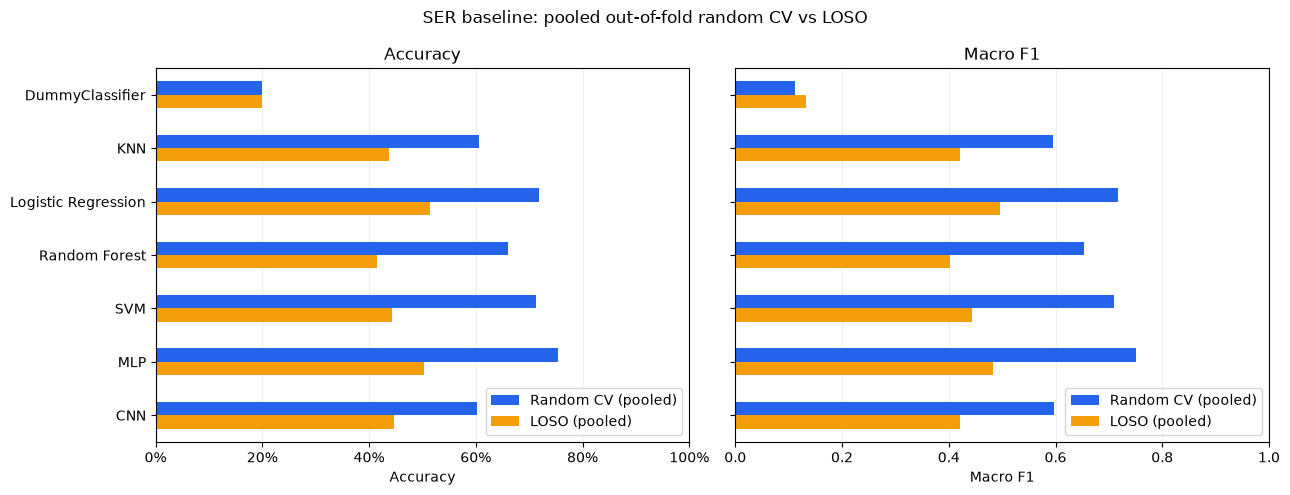

In [14]:
def summarise_predictions(records):
    """Return pooled OOF scores, individual fold scores, and fold mean/sample std."""
    fold_rows, pooled_rows = [], []
    class_labels = np.arange(len(encoder.classes_))
    for record in records:
        indices, actual, predicted = record['Indices'],record['Actual'],record['Predicted']
        if len(indices)!=len(actual) or len(actual)!=len(predicted):
            raise ValueError('Prediction lengths do not match the held-out recording indices.')
        np.testing.assert_array_equal(actual,y[indices])
        fold_rows.append({'Model':record['Model'], 'Protocol':record['Protocol'],
            'Fold':record['Fold'], 'Test clips':len(actual),
            'Accuracy':accuracy_score(actual,predicted),
            'Macro F1':f1_score(actual,predicted,average='macro',labels=class_labels,zero_division=0)})
    for name in [*models,'CNN']:
        row = {'Model':name}
        for setting in ['Random','LOSO']:
            chosen = [record for record in records if record['Model']==name and record['Protocol']==setting]
            if not chosen:
                raise ValueError(f'Missing out-of-fold predictions: {name}, {setting}.')
            indices = np.concatenate([record['Indices'] for record in chosen])
            if not np.array_equal(np.sort(indices),np.arange(len(y))):
                raise ValueError(f'{name}, {setting}: every recording must be tested exactly once.')
            if len({record['Fold'] for record in chosen})!=len(chosen):
                raise ValueError(f'Duplicate fold predictions: {name}, {setting}.')
            actual = np.concatenate([record['Actual'] for record in chosen])
            predicted = np.concatenate([record['Predicted'] for record in chosen])
            row[f'{setting} accuracy'] = accuracy_score(actual,predicted)
            row[f'{setting} macro F1'] = f1_score(actual,predicted,average='macro',
                                                 labels=class_labels,zero_division=0)
        pooled_rows.append(row)
    pooled = pd.DataFrame(pooled_rows).set_index('Model')
    per_fold = pd.DataFrame(fold_rows)
    fold_stats = per_fold.groupby(['Model','Protocol'],sort=False).agg(
        Folds=('Accuracy','size'), Accuracy_mean=('Accuracy','mean'),
        Accuracy_std=('Accuracy','std'), Macro_F1_mean=('Macro F1','mean'),
        Macro_F1_std=('Macro F1','std'))
    fold_stats.columns = ['Folds','Accuracy mean','Accuracy std','Macro F1 mean','Macro F1 std']
    fold_stats = fold_stats.reindex(pd.MultiIndex.from_product(
        [[*models,'CNN'],['Random','LOSO']],names=['Model','Protocol']))
    return pooled,per_fold,fold_stats

def show_fold_statistics(table,caption):
    view = table[['Folds']].copy()
    view['Accuracy (mean ± std)'] = [f'{mean:.1%} ± {std:.1%}'
                                    for mean,std in zip(table['Accuracy mean'],table['Accuracy std'])]
    view['Macro F1 (mean ± std)'] = [f'{mean:.3f} ± {std:.3f}'
                                    for mean,std in zip(table['Macro F1 mean'],table['Macro F1 std'])]
    display(view.style.set_caption(caption+' — sample std, ddof=1'))

if len(trained_splits)!=len(scaled_splits):
    raise RuntimeError('Re-run section 7 to train models for every current outer fold.')
predictions, prediction_records, baseline_training_rows = [], [], []
for fold,fitted in zip(scaled_splits,trained_splits):
    for name,model in fitted.items():
        if name=='CNN':
            predicted = cnn_predict(model, fold['Z_test'])
            training_predicted = cnn_predict(model, fold['Z_train'])
        else:
            predicted = model.predict(fold['X_test'])
            training_predicted = model.predict(fold['X_train'])
        baseline_training_rows.append({'Model':name, 'Protocol':fold['setting'], 'Fold':fold['name'],
            'Training accuracy':accuracy_score(fold['y_train'],training_predicted),
            'Training macro F1':f1_score(fold['y_train'],training_predicted,average='macro',
                                       labels=np.arange(len(encoder.classes_)),zero_division=0),
            'Test accuracy':accuracy_score(fold['y_test'],predicted),
            'Test macro F1':f1_score(fold['y_test'],predicted,average='macro',
                                   labels=np.arange(len(encoder.classes_)),zero_division=0)})
        predictions.append((fold['setting'],name,fold['y_test'].copy(),predicted.copy()))
        prediction_records.append({'Protocol':fold['setting'],'Fold':fold['name'],'Model':name,
            'Indices':fold['test'].copy(),'Actual':fold['y_test'].copy(),'Predicted':predicted.copy()})
summary,fold_scores,fold_summary = summarise_predictions(prediction_records)
display(summary.style.format({
    'Random accuracy':'{:.1%}','Random macro F1':'{:.3f}',
    'LOSO accuracy':'{:.1%}','LOSO macro F1':'{:.3f}'
}).set_caption(f'Pooled out-of-fold baseline — {FEATURE_SET} ({X.shape[1]} features); random 5-fold CV and LOSO; CNN {CNN_INPUT_NAME}'))
show_fold_statistics(fold_summary,'Baseline fold mean and standard deviation')
baseline_training_scores = pd.DataFrame(baseline_training_rows)
baseline_training_summary = baseline_training_scores.groupby(['Model','Protocol'],sort=False)[
    ['Training accuracy','Training macro F1','Test accuracy','Test macro F1']].mean()
display(Markdown('**Baseline diagnostics: mean training/test scores across outer folds**'))
display(baseline_training_summary.style.format({
    'Training accuracy':'{:.1%}', 'Test accuracy':'{:.1%}',
    'Training macro F1':'{:.3f}', 'Test macro F1':'{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, metric, columns in zip(axes, ['Accuracy', 'Macro F1'],
        [['Random accuracy', 'LOSO accuracy'], ['Random macro F1', 'LOSO macro F1']]):
    values = summary[columns].copy()
    values.columns = ['Random CV (pooled)', 'LOSO (pooled)']
    values.plot.barh(ax=ax, color=['#2563eb', '#f59e0b'])
    ax.set(title=metric, xlabel=metric, ylabel='', xlim=(0, 1))
    ax.grid(axis='x', alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend(loc='lower right')
axes[0].invert_yaxis()
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('SER baseline: pooled out-of-fold random CV vs LOSO')
fig.tight_layout()
plt.show()

## 9. Model Optimisation & Hyperparameter Tuning

Keep the input preset, all its features and the outer splits fixed. Tune model
hyperparameters without selecting feature subsets. Each subsection
shows its search space, validation results and selected settings. DummyClassifier
remains the reference; it is not tuned. Outer-test scores are calculated only in
section 10 for the optimised models, after all selections have been made.

### 9.1 Baseline results

Preserve pooled scores, fold statistics and indexed predictions from section 8
for the selected feature set. Both stages reuse all five random and six LOSO folds.
This is a snapshot, not a second baseline training run. To compare basic and rich
feature modes, run sections 4–10 separately for each choice and record both runs.

In [15]:
baseline_summary = summary.copy(deep=True)
baseline_predictions = [(setting, name, actual.copy(), predicted.copy())
                        for setting, name, actual, predicted in predictions]
baseline_prediction_records = [{key:(value.copy() if isinstance(value,np.ndarray) else value)
                                for key,value in record.items()} for record in prediction_records]
baseline_fold_scores = fold_scores.copy(deep=True)
baseline_fold_summary = fold_summary.copy(deep=True)
baseline_feature_set = FEATURE_SET
baseline_feature_count = X.shape[1]
baseline_cnn_shape = tuple(Z.shape[1:])
baseline_cnn_input = CNN_INPUT_NAME
model_order = [*models, 'CNN']
metric_format = {'Random accuracy':'{:.1%}', 'Random macro F1':'{:.3f}',
                 'LOSO accuracy':'{:.1%}', 'LOSO macro F1':'{:.3f}'}
display(baseline_summary.style.format(metric_format).set_caption(
    f'Pooled out-of-fold baseline — {baseline_feature_set}, {baseline_feature_count} features; CNN {baseline_cnn_input}'))
show_fold_statistics(baseline_fold_summary,'Baseline fold mean and standard deviation')
display(pd.DataFrame([
    {'Model':name, 'Baseline settings':repr(estimator)}
    for name, estimator in models.items()
] + [{'Model':'CNN', 'Baseline settings':f'{Z.shape[1]} input channels ({CNN_INPUT_NAME}), Conv 16/32 + BatchNorm, adaptive 4x4, Dense 64, dropout 0.4, Adam lr=0.001, weight_decay=0.0001, max {CNN_MAX_EPOCHS} epochs; inner-validation-calibrated refit'}]))
display(Markdown('**Baseline training/test diagnostics — unweighted fold means**'))
display(baseline_training_summary.round(4))

,Random accuracy,Random macro F1,LOSO accuracy,LOSO macro F1
Model,,,,
DummyClassifier,19.9%,0.112,19.9%,0.133
KNN,60.6%,0.596,43.7%,0.422
Logistic Regression,71.9%,0.717,51.5%,0.497
Random Forest,66.1%,0.654,41.6%,0.403
SVM,71.2%,0.709,44.4%,0.444
MLP,75.3%,0.750,50.3%,0.484
CNN,60.3%,0.597,44.7%,0.422


,Model,Baseline settings
0,DummyClassifier,DummyClassifier()
1,KNN,KNeighborsClassifier()
2,Logistic Regression,LogisticRegression()
3,Random Forest,RandomForestClassifier()
4,SVM,SVC()
5,MLP,TorchMLPClassifier()
6,CNN,"3 input channels (Log-mel + Delta + Delta-delta), Conv 16/32 + BatchNorm, adaptive 4x4, Dense 64, dropout 0.4, Adam lr=0.001, weight_decay=0.0001, max 50 epochs; inner-validation-calibrated refit"


**Baseline training/test diagnostics — unweighted fold means**

,,Training accuracy,Training macro F1,Test accuracy,Test macro F1
Model,Protocol,,,,
DummyClassifier,Random,0.2028,0.0674,0.1987,0.0663
KNN,Random,0.7438,0.7382,0.6060,0.5942
Logistic Regression,Random,0.9917,0.9917,0.7186,0.7152
Random Forest,Random,1.0000,1.0000,0.6607,0.6532
SVM,Random,0.9478,0.9480,0.7120,0.7066
MLP,Random,1.0000,1.0000,0.7533,0.7492
CNN,Random,0.7934,0.7896,0.6025,0.5958
DummyClassifier,LOSO,0.2023,0.0673,0.1987,0.0663
KNN,LOSO,0.7414,0.7365,0.4374,0.4044


### 9.2 Optimisation method

Tune separately inside every outer training split: five random folds and six
LOSO folds. Shared inner validation (configured in section 7) uses **four stratified group random folds**
and **all remaining speakers** for LOSO (five inner holdouts for AESDD).
The outer test speaker never enters inner training or validation. A coverage
table shows how often each speaker serves as an inner validation holdout.

Feature-vector models tune settings using `Pipeline(StandardScaler, model)`.
KNN, Logistic Regression, Random Forest and SVM use exhaustive grid search.
MLP uses a cloneable PyTorch estimator with balanced random sampling: three
Adam and three L-BFGS configurations per architecture. `ParameterSampler`
draws the candidates once with seeds 42/43; singleton grids let the same CV runner
evaluate only those 24 candidates and perform one selected outer refit.
This is a randomised search, not the full 120-configuration grid.
Every candidate uses all features from the section 4 preset: 40 MFCC features
in basic mode or all 120 acoustic features in rich mode. This same fixed
representation is used for the baseline and every tuned model and outer fold.
The global basic/rich toggle continues to control both model families.

Every inner fold fits its own scaler, and every selected pipeline refits on all
outer training clips. CNN channel normalisation follows the same training-only
rule. Section 6's outer-scaled arrays are not used for inner tuning.

Select classical settings and CNN candidates by **mean inner-validation macro F1**;
retain accuracy as a second metric. For CNN, lowest inner-validation loss chooses
each checkpoint. Its macro F1 enters candidate selection. Median checkpoint
epoch and validation-derived learning-rate schedules determine a fresh outer
training refit. No outer test data select settings, checkpoints or epoch counts.

Tables display complete settings and training/validation scores. Each classical
section plots the selected candidates' mean inner-training versus validation
macro F1; these are diagnostics, not outer evaluation scores. Training F1 alone,
particularly for distance-weighted KNN, is not evidence of generalisation.

`TUNING_JOBS = 6` runs up to six classical candidate/fold fits concurrently.
RF keeps its tree-level n_jobs=1 to avoid nested parallelism; reduce the
shared job count if CPU/RAM capacity is limited. Tuned
PyTorch MLP always uses one fitting job; MLP and CNN automatically use CPU/CUDA.
Baseline and tuned MLP use the same PyTorch class, training-loss stopping rule
and shared 1500-iteration upper limit from section 7. The five sklearn baselines
stay unchanged. Full speaker validation can be lengthy. The CNN
baseline now uses matched architecture components and validation stopping.
CNN epoch/stopping and inner-split settings are shared with section 7. Changing
them requires rerunning sections 7–10. Re-running this cell alone clears tuning
state, so re-run 9.3–10 afterwards.

Every model displays **Top 10 & Bottom 10 candidates**, separately across all
Random folds and all LOSO folds. Rank by the unweighted mean of each
candidate's inner-validation macro F1 across that protocol's outer folds. 
Show across-outer-fold sample standard
deviation, fold coverage and selected-fold count. These are inner-validation
diagnostics, not pooled F1 or outer-test results, and do not change selection.
Top/bottom lists can overlap when fewer than twenty candidates exist.

In [16]:
from time import perf_counter
import json
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.metrics import make_scorer

TUNING_SEED = CNN_SEED
TUNING_JOBS = 6
# CNN/inner-split constants and helpers come from section 7, shared with the baseline.
if cnn_protocol_settings() != baseline_cnn_protocol:
    raise RuntimeError('CNN/inner validation settings changed: rerun sections 7–10.')
if (not isinstance(models['MLP'], TorchMLPClassifier)
        or models['MLP'].max_iter != MLP_MAX_ITER or models['MLP'].device != MLP_DEVICE):
    raise RuntimeError('MLP baseline implementation or shared limits changed: rerun sections 7–10.')

if (FEATURE_SET != baseline_feature_set or X.shape[1] != baseline_feature_count
        or tuple(Z.shape[1:]) != baseline_cnn_shape):
    raise RuntimeError('Feature preset changed: re-run sections 4–9.1 before tuning.')
labels = np.arange(len(encoder.classes_))
macro_f1_scorer = make_scorer(f1_score, average='macro', labels=labels, zero_division=0)

def format_settings(params):
    readable = {key.removeprefix('model__'):value for key, value in params.items()}
    return json.dumps(readable)

tuning_folds, validation_rows = [], []
for fold in scaled_splits:
    outer_train, outer_test = fold['train'], fold['test']
    subset = metadata.iloc[outer_train]
    inner = make_inner_splits(outer_train,fold['setting'],seed=TUNING_SEED)
    group_column = 'group' if fold['setting']=='Random' else 'speaker'
    baseline_inner = baseline_cnn_bundles[fold['name']]['inner_splits']
    if len(inner) != len(baseline_inner) or any(
            not np.array_equal(tr,old_tr) or not np.array_equal(va,old_va)
            for (tr,va),(old_tr,old_va) in zip(inner,baseline_inner)):
        raise RuntimeError('Inner folds changed: rerun sections 7–10.')
    for inner_id, (train_idx, valid_idx) in enumerate(inner, start=1):
        train_global, valid_global = outer_train[train_idx], outer_train[valid_idx]
        assert not set(train_global) & set(valid_global)
        assert not (set(train_global) | set(valid_global)) & set(outer_test)
        assert not set(subset[group_column].iloc[train_idx]) & set(subset[group_column].iloc[valid_idx])
        if len(np.unique(y[train_global])) != len(labels):
            raise ValueError('An inner training fold is missing an emotion; review the split design.')
        validation_rows.append({'Outer split':fold['name'], 'Protocol':fold['setting'], 'Inner fold':inner_id,
            'Train clips':len(train_idx), 'Validation clips':len(valid_idx),
            'Validation speakers':','.join(sorted(subset.speaker.iloc[valid_idx].unique())),
            'Group rule':group_column})
    tuning_folds.append({'name':fold['name'], 'setting':fold['setting'],
                         'train':outer_train.copy(), 'test':outer_test.copy(), 'inner':inner})
optimised_models = {fold['name']:{'DummyClassifier':trained_splits[i]['DummyClassifier']}
                   for i, fold in enumerate(tuning_folds)}
validation_results, selected_settings = {}, []
validation_plan = pd.DataFrame(validation_rows)
display(validation_plan)
display(Markdown('**Inner LOSO validation coverage across outer folds**'))
coverage = validation_plan.loc[validation_plan.Protocol == 'LOSO', 'Validation speakers'].str.split(',').explode()
display(coverage.value_counts().sort_index().rename_axis('Speaker').to_frame('Validation holdouts'))
display(pd.DataFrame([{'Selection metric':'Mean inner-validation macro F1',
    'Acoustic features':X.shape[1], 'Feature set':FEATURE_SET,
    'CNN input':CNN_INPUT_NAME, 'CNN channels':Z.shape[1],
    'Random outer folds':sum(fold['setting']=='Random' for fold in tuning_folds),
    'LOSO outer folds':sum(fold['setting']=='LOSO' for fold in tuning_folds),
    'Random inner folds':INNER_RANDOM_FOLDS, 'LOSO inner holdouts':INNER_LOSO_FOLDS or 'All',
    'CNN max epochs':CNN_MAX_EPOCHS, 'CNN patience':CNN_PATIENCE, 'CNN device':str(DEVICE)}]))

def show_candidate_rankings(name, table, n=10):
    """Show best/worst candidate means across outer folds, separately for each protocol."""
    rankings = {}
    for protocol in ['Random', 'LOSO']:
        rows = table.loc[table['Protocol'].eq(protocol)]
        if rows.empty:
            continue
        scores = rows.groupby('Settings', sort=False).agg(**{
            'Mean inner-validation macro F1':('Validation macro F1', 'mean'),
            'Across-outer-fold F1 std':('Validation macro F1', 'std'),
            'Outer folds':('Outer split', 'nunique'),
            'Selected folds':('Selected', 'sum')
        }).reset_index()
        display(Markdown(f'**Top {n} & Bottom {n} candidates: across all {protocol} '
            f'folds by validation macro F1 — {name}**'))
        rankings[protocol] = {}
        for label, ascending in [('Top', False), ('Bottom', True)]:
            ranked = (scores.sort_values(['Mean inner-validation macro F1', 'Settings'],
                                         ascending=[ascending, True])
                      .head(n).reset_index(drop=True))
            ranked.index = np.arange(1, len(ranked)+1)
            ranked.index.name = 'Rank'
            rankings[protocol][label] = ranked
            display(Markdown(f'**{label} {len(ranked)} candidates**'))
            display(ranked.round(4))
    return rankings

def tune_classical(name, estimator, param_grid, search_method='GridSearchCV', n_jobs=None):
    candidate_tables, selections = [], []
    jobs = TUNING_JOBS if n_jobs is None else n_jobs
    display(pd.DataFrame([{'Model':name, 'Implementation':type(estimator).__name__,
        'Search method':search_method, 'Candidates':len(ParameterGrid(param_grid)), 'Jobs':jobs}]))
    selected_settings[:] = [row for row in selected_settings if row['Model'] != name]
    display(pd.DataFrame([{'Candidate':i+1, 'Settings':format_settings(params)}
                         for i, params in enumerate(ParameterGrid(param_grid))]))
    for fold in tuning_folds:
        display(Markdown(f"**{name}: {fold['name']}** — tuning on outer training data"))
        pipeline = Pipeline([('scale', StandardScaler()), ('model', clone(estimator))])
        search = GridSearchCV(pipeline, param_grid, cv=fold['inner'],
            scoring={'accuracy':'accuracy', 'macro_f1':macro_f1_scorer}, refit='macro_f1',
            n_jobs=jobs, error_score='raise', return_train_score=True)
        np.random.seed(TUNING_SEED)
        started = perf_counter()
        search.fit(X[fold['train']], y[fold['train']])
        elapsed = perf_counter()-started
        optimised_models[fold['name']][name] = search.best_estimator_
        result = search.cv_results_
        candidate_tables.append(pd.DataFrame({
            'Outer split':fold['name'], 'Protocol':fold['setting'],
            'Candidate':np.arange(1, len(result['params'])+1),
            'Implementation':type(estimator).__name__, 'Search method':search_method,
            'Settings':[format_settings(p) for p in result['params']],
            'Validation macro F1':result['mean_test_macro_f1'],
            'Validation F1 std':result['std_test_macro_f1'],
            'Validation accuracy':result['mean_test_accuracy'],
            'Training macro F1':result['mean_train_macro_f1'],
            'Training accuracy':result['mean_train_accuracy'],
            'Train-validation F1 gap':result['mean_train_macro_f1']-result['mean_test_macro_f1'],
            'Selected':np.arange(len(result['params'])) == search.best_index_
        }))
        selected = search.best_index_
        row = {'Model':name, 'Outer split':fold['name'], 'Protocol':fold['setting'], 'Feature set':FEATURE_SET,
            'Feature count':X.shape[1],
            'Implementation':type(estimator).__name__, 'Search method':search_method,
            'Selected settings':format_settings(search.best_params_), 'Validation macro F1':search.best_score_,
            'Validation accuracy':result['mean_test_accuracy'][selected],
            'Training macro F1':result['mean_train_macro_f1'][selected],
            'Train-validation F1 gap':result['mean_train_macro_f1'][selected]-search.best_score_,
            'Inner folds':len(fold['inner']), 'Search seconds':elapsed}
        selections.append(row)
        selected_settings.append(row)
    table = pd.concat(candidate_tables, ignore_index=True)
    validation_results[name] = table
    show_candidate_rankings(name, table)
    display(Markdown('**Selected configuration for each outer split**'))
    display(pd.DataFrame(selections).round(4))
    chosen = table[table.Selected]
    diagnostics = chosen.groupby('Protocol')[['Training macro F1', 'Validation macro F1',
                                             'Train-validation F1 gap']].mean().reindex(['Random','LOSO'])
    display(Markdown('**Selected candidates: mean inner-training and validation scores across outer folds**'))
    display(diagnostics.round(4))
    ax = diagnostics[['Training macro F1','Validation macro F1']].plot.bar(
        figsize=(7,3.5), color=['#94a3b8','#2563eb'], rot=0, ylim=(0,1))
    ax.set(title=f'{name}: inner-training versus validation', ylabel='Macro F1', xlabel='Protocol')
    ax.figure.tight_layout()
    plt.show()
    return table

,Outer split,Protocol,Inner fold,Train clips,Validation clips,Validation speakers,Group rule
0,Random: fold 1,Random,1,362,121,"1,2,3,4,5,6",group
1,Random: fold 1,Random,2,363,120,"1,2,3,4,5,6",group
2,Random: fold 1,Random,3,362,121,"1,2,3,4,5,6",group
3,Random: fold 1,Random,4,362,121,"1,2,3,4,5,6",group
4,Random: fold 2,Random,1,362,121,"1,2,3,4,5,6",group
5,Random: fold 2,Random,2,363,120,"1,2,3,4,5,6",group
6,Random: fold 2,Random,3,362,121,"1,2,3,4,5,6",group
7,Random: fold 2,Random,4,362,121,"1,2,3,4,5,6",group
8,Random: fold 3,Random,1,363,121,"1,2,3,4,5,6",group
9,Random: fold 3,Random,2,363,121,"1,2,3,4,5,6",group


**Inner LOSO validation coverage across outer folds**

,Validation holdouts
Speaker,
1,5
2,5
3,5
4,5
5,5
6,5


,Selection metric,Acoustic features,Feature set,CNN input,CNN channels,Random outer folds,LOSO outer folds,Random inner folds,LOSO inner holdouts,CNN max epochs,CNN patience,CNN device
0,Mean inner-validation macro F1,120,rich,Log-mel + Delta + Delta-delta,3,5,6,4,All,50,15,cuda


### 9.3 KNN optimisation

Baseline: 5 neighbours, uniform weights and Euclidean distance. Compare
**3/5/7/9/11** neighbours, uniform/distance weighting and Manhattan/Euclidean
distance. This gives 20 model combinations, each using all features from the
selected basic/rich preset. Inner validation chooses each outer fold's settings.

,Model,Implementation,Search method,Candidates,Jobs
0,KNN,KNeighborsClassifier,GridSearchCV,20,6


,Candidate,Settings
0,1,"{""n_neighbors"": 3, ""p"": 1, ""weights"": ""uniform""}"
1,2,"{""n_neighbors"": 3, ""p"": 1, ""weights"": ""distance""}"
2,3,"{""n_neighbors"": 3, ""p"": 2, ""weights"": ""uniform""}"
3,4,"{""n_neighbors"": 3, ""p"": 2, ""weights"": ""distance""}"
4,5,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""uniform""}"
5,6,"{""n_neighbors"": 5, ""p"": 1, ""weights"": ""distance""}"
6,7,"{""n_neighbors"": 5, ""p"": 2, ""weights"": ""uniform""}"
7,8,"{""n_neighbors"": 5, ""p"": 2, ""weights"": ""distance""}"
8,9,"{""n_neighbors"": 7, ""p"": 1, ""weights"": ""uniform""}"
9,10,"{""n_neighbors"": 7, ""p"": 1, ""weights"": ""distance""}"


**KNN: Random: fold 1** — tuning on outer training data

**KNN: Random: fold 2** — tuning on outer training data

**KNN: Random: fold 3** — tuning on outer training data

**KNN: Random: fold 4** — tuning on outer training data

... (17 outputs left out)

**Selected configuration for each outer split**

,Model,Outer split,Protocol,Feature set,Feature count,Implementation,Search method,Selected settings,Validation macro F1,Validation accuracy,Training macro F1,Train-validation F1 gap,Inner folds,Search seconds
0,KNN,Random: fold 1,Random,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 7, ""p"": 2, ""weights"": ""uniform""}",0.6298,0.6356,0.7133,0.0835,4,9.4049
1,KNN,Random: fold 2,Random,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 9, ""p"": 1, ""weights"": ""distance""}",0.6296,0.6439,1.0000,0.3704,4,0.1884
2,KNN,Random: fold 3,Random,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 7, ""p"": 1, ""weights"": ""distance""}",0.6288,0.6405,1.0000,0.3712,4,0.1842
3,KNN,Random: fold 4,Random,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 9, ""p"": 1, ""weights"": ""uniform""}",0.6072,0.6169,0.7150,0.1078,4,0.1839
4,KNN,Random: fold 5,Random,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 11, ""p"": 1, ""weights"": ""distance""}",0.6020,0.6170,1.0000,0.3980,4,0.1835
5,KNN,LOSO: speaker 1,LOSO,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 3, ""p"": 1, ""weights"": ""distance""}",0.3915,0.4286,1.0000,0.6085,5,0.2242
6,KNN,LOSO: speaker 2,LOSO,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 9, ""p"": 2, ""weights"": ""uniform""}",0.3922,0.4248,0.7283,0.3361,5,0.2400
7,KNN,LOSO: speaker 3,LOSO,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 3, ""p"": 2, ""weights"": ""distance""}",0.3319,0.3672,1.0000,0.6681,5,0.2403
8,KNN,LOSO: speaker 4,LOSO,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 5, ""p"": 2, ""weights"": ""uniform""}",0.3795,0.3991,0.7127,0.3332,5,0.2251
9,KNN,LOSO: speaker 5,LOSO,rich,120,KNeighborsClassifier,GridSearchCV,"{""n_neighbors"": 5, ""p"": 2, ""weights"": ""distance""}",0.4039,0.4412,1.0000,0.5961,5,0.2324


**Selected candidates: mean inner-training and validation scores across outer folds**

,Training macro F1,Validation macro F1,Train-validation F1 gap
Protocol,,,
Random,0.8857,0.6195,0.2662
LOSO,0.9068,0.3894,0.5174


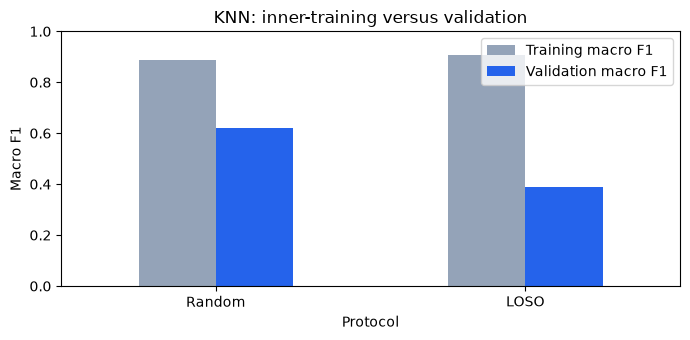

In [17]:
knn_grid = {'model__n_neighbors':[3,5,7,9,11], 'model__weights':['uniform','distance'],
            'model__p':[1,2]}
knn_validation = tune_classical('KNN', KNeighborsClassifier(), knn_grid)

### 9.4 Logistic Regression optimisation

Search 12 C values: `0.001/0.005/0.01/0.05/0.1/0.5/1/5/10/50/100/200`,
all with `max_iter=1500`. There is no separate 100-iteration reference candidate.
Lower C means stronger regularisation. Every candidate uses all features from
the selected preset. More iterations allow convergence but do not guarantee
higher held-out scores. The section 7 default baseline remains unchanged.

,Model,Implementation,Search method,Candidates,Jobs
0,Logistic Regression,LogisticRegression,GridSearchCV,12,6


,Candidate,Settings
0,1,"{""C"": 0.001, ""max_iter"": 1500}"
1,2,"{""C"": 0.005, ""max_iter"": 1500}"
2,3,"{""C"": 0.01, ""max_iter"": 1500}"
3,4,"{""C"": 0.05, ""max_iter"": 1500}"
4,5,"{""C"": 0.1, ""max_iter"": 1500}"
5,6,"{""C"": 0.5, ""max_iter"": 1500}"
6,7,"{""C"": 1, ""max_iter"": 1500}"
7,8,"{""C"": 5, ""max_iter"": 1500}"
8,9,"{""C"": 10, ""max_iter"": 1500}"
9,10,"{""C"": 50, ""max_iter"": 1500}"


**Logistic Regression: Random: fold 1** — tuning on outer training data

**Logistic Regression: Random: fold 2** — tuning on outer training data

**Logistic Regression: Random: fold 3** — tuning on outer training data

**Logistic Regression: Random: fold 4** — tuning on outer training data

... (17 outputs left out)

**Selected configuration for each outer split**

,Model,Outer split,Protocol,Feature set,Feature count,Implementation,Search method,Selected settings,Validation macro F1,Validation accuracy,Training macro F1,Train-validation F1 gap,Inner folds,Search seconds
0,Logistic Regression,Random: fold 1,Random,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.5, ""max_iter"": 1500}",0.7077,0.7079,0.9896,0.2820,4,0.2599
1,Logistic Regression,Random: fold 2,Random,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.1, ""max_iter"": 1500}",0.7085,0.7122,0.9500,0.2415,4,0.2313
2,Logistic Regression,Random: fold 3,Random,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.05, ""max_iter"": 1500}",0.6976,0.7026,0.9068,0.2092,4,0.1980
3,Logistic Regression,Random: fold 4,Random,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.1, ""max_iter"": 1500}",0.7158,0.7184,0.9426,0.2269,4,0.1881
4,Logistic Regression,Random: fold 5,Random,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.5, ""max_iter"": 1500}",0.7156,0.7164,0.9931,0.2774,4,0.1852
5,Logistic Regression,LOSO: speaker 1,LOSO,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.5, ""max_iter"": 1500}",0.3910,0.4378,0.9950,0.6041,5,0.2402
6,Logistic Regression,LOSO: speaker 2,LOSO,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.01, ""max_iter"": 1500}",0.4654,0.5009,0.8411,0.3757,5,0.2009
7,Logistic Regression,LOSO: speaker 3,LOSO,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.5, ""max_iter"": 1500}",0.4407,0.4835,0.9906,0.5499,5,0.2221
8,Logistic Regression,LOSO: speaker 4,LOSO,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.05, ""max_iter"": 1500}",0.4724,0.5033,0.9077,0.4353,5,0.2155
9,Logistic Regression,LOSO: speaker 5,LOSO,rich,120,LogisticRegression,GridSearchCV,"{""C"": 0.1, ""max_iter"": 1500}",0.5021,0.5376,0.9527,0.4506,5,0.2062


**Selected candidates: mean inner-training and validation scores across outer folds**

,Training macro F1,Validation macro F1,Train-validation F1 gap
Protocol,,,
Random,0.9564,0.7090,0.2474
LOSO,0.9478,0.4688,0.4789


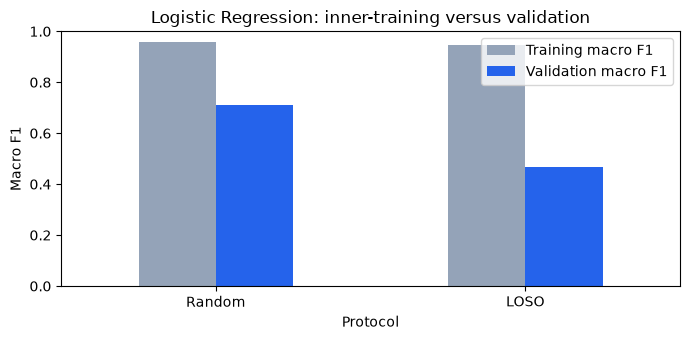

In [18]:
lr_grid = [
    {'model__C':[0.001,0.005,0.01,0.05,0.1,0.5,1,5,10,50,100,200], 'model__max_iter':[1500]}
]
lr_validation = tune_classical('Logistic Regression', LogisticRegression(), lr_grid)

### 9.5 Random Forest optimisation

Exhaustively compare **54 configurations**: 100/200 trees, unrestricted or
10/20 maximum depth, minimum leaf sizes 1/2/4, and
`max_features='sqrt'/0.5/1.0`. Fractions specify the share of input
features considered per split. More trees stabilise voting; depth and leaf size
control tree complexity, while max_features controls split diversity.
All candidates retain every input feature; max_features
acts inside each tree, not as a preprocessing feature selector. Use seed 42.

,Model,Implementation,Search method,Candidates,Jobs
0,Random Forest,RandomForestClassifier,GridSearchCV,54,6


,Candidate,Settings
0,1,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1, ""n_estimators"": 100}"
1,2,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1, ""n_estimators"": 200}"
2,3,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 100}"
3,4,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 200}"
4,5,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 4, ""n_estimators"": 100}"
5,6,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 4, ""n_estimators"": 200}"
6,7,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators"": 100}"
7,8,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators"": 200}"
8,9,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 2, ""n_estimators"": 100}"
9,10,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 2, ""n_estimators"": 200}"


**Random Forest: Random: fold 1** — tuning on outer training data

**Random Forest: Random: fold 2** — tuning on outer training data

**Random Forest: Random: fold 3** — tuning on outer training data

**Random Forest: Random: fold 4** — tuning on outer training data

... (17 outputs left out)

**Selected configuration for each outer split**

,Model,Outer split,Protocol,Feature set,Feature count,Implementation,Search method,Selected settings,Validation macro F1,Validation accuracy,Training macro F1,Train-validation F1 gap,Inner folds,Search seconds
0,Random Forest,Random: fold 1,Random,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 200}",0.6460,0.6500,1.000,0.3540,4,27.1403
1,Random Forest,Random: fold 2,Random,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1, ""n_estimators"": 200}",0.6605,0.6667,1.000,0.3395,4,28.6053
2,Random Forest,Random: fold 3,Random,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 200}",0.6498,0.6571,1.000,0.3502,4,30.2870
3,Random Forest,Random: fold 4,Random,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": ""sqrt"", ""min_samples_leaf"": 2, ""n_estimators"": 100}",0.6394,0.6439,1.000,0.3606,4,28.7853
4,Random Forest,Random: fold 5,Random,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": 10, ""max_features"": ""sqrt"", ""min_samples_leaf"": 1, ""n_estimators"": 200}",0.6663,0.6730,1.000,0.3337,4,28.8382
5,Random Forest,LOSO: speaker 1,LOSO,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators"": 200}",0.3551,0.4063,1.000,0.6449,5,42.1775
6,Random Forest,LOSO: speaker 2,LOSO,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": 1.0, ""min_samples_leaf"": 2, ""n_estimators"": 100}",0.3788,0.4061,0.999,0.6202,5,42.0198
7,Random Forest,LOSO: speaker 3,LOSO,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators"": 100}",0.3402,0.3918,1.000,0.6598,5,41.0816
8,Random Forest,LOSO: speaker 4,LOSO,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": 10, ""max_features"": 0.5, ""min_samples_leaf"": 1, ""n_estimators"": 100}",0.3729,0.4073,1.000,0.6271,5,43.0791
9,Random Forest,LOSO: speaker 5,LOSO,rich,120,RandomForestClassifier,GridSearchCV,"{""max_depth"": null, ""max_features"": 0.5, ""min_samples_leaf"": 2, ""n_estimators"": 200}",0.4417,0.4768,1.000,0.5583,5,39.7653


**Selected candidates: mean inner-training and validation scores across outer folds**

,Training macro F1,Validation macro F1,Train-validation F1 gap
Protocol,,,
Random,1.0000,0.6524,0.3476
LOSO,0.9998,0.3908,0.6090


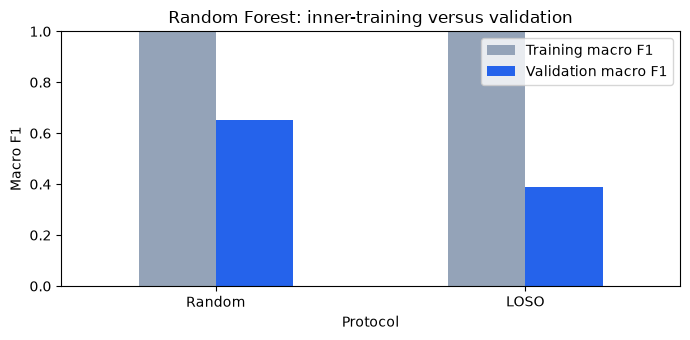

In [19]:
rf_grid = {
    'model__n_estimators':[100,200],              # Number of trees
    'model__max_depth':[None,10,20],               # Maximum depth; None is unrestricted
    'model__min_samples_leaf':[1,2,4],          # Minimum training samples per leaf
    'model__max_features':['sqrt',0.5,1.0]        # Features considered per split
}
rf_validation = tune_classical('Random Forest',
    RandomForestClassifier(random_state=TUNING_SEED, n_jobs=1), rf_grid)

### 9.6 SVM optimisation

Search 10 C values: `0.01/0.05/0.1/0.5/1/5/10/50/100/1000`.
For RBF, also search seven gamma values:
`'scale'/0.00001/0.0001/0.0005/0.001/0.005/0.01`.
This gives 70 RBF and 10 linear candidates: **80 total**.
The linear branch searches only C, avoiding irrelevant gamma evaluations.
C controls regularisation and gamma controls RBF locality; tune them jointly.
Every candidate uses all preset features.

,Model,Implementation,Search method,Candidates,Jobs
0,SVM,SVC,GridSearchCV,80,6


,Candidate,Settings
0,1,"{""C"": 0.01, ""gamma"": ""scale"", ""kernel"": ""rbf""}"
1,2,"{""C"": 0.01, ""gamma"": 1e-05, ""kernel"": ""rbf""}"
2,3,"{""C"": 0.01, ""gamma"": 0.0001, ""kernel"": ""rbf""}"
3,4,"{""C"": 0.01, ""gamma"": 0.0005, ""kernel"": ""rbf""}"
4,5,"{""C"": 0.01, ""gamma"": 0.001, ""kernel"": ""rbf""}"
...,...,...
75,76,"{""C"": 5, ""kernel"": ""linear""}"
76,77,"{""C"": 10, ""kernel"": ""linear""}"
77,78,"{""C"": 50, ""kernel"": ""linear""}"
78,79,"{""C"": 100, ""kernel"": ""linear""}"


**SVM: Random: fold 1** — tuning on outer training data

**SVM: Random: fold 2** — tuning on outer training data

**SVM: Random: fold 3** — tuning on outer training data

**SVM: Random: fold 4** — tuning on outer training data

... (17 outputs left out)

**Selected configuration for each outer split**

,Model,Outer split,Protocol,Feature set,Feature count,Implementation,Search method,Selected settings,Validation macro F1,Validation accuracy,Training macro F1,Train-validation F1 gap,Inner folds,Search seconds
0,SVM,Random: fold 1,Random,rich,120,SVC,GridSearchCV,"{""C"": 100, ""gamma"": 0.001, ""kernel"": ""rbf""}",0.7167,0.7205,1.0000,0.2833,4,1.3417
1,SVM,Random: fold 2,Random,rich,120,SVC,GridSearchCV,"{""C"": 50, ""gamma"": 0.005, ""kernel"": ""rbf""}",0.7328,0.7371,1.0000,0.2672,4,1.3222
2,SVM,Random: fold 3,Random,rich,120,SVC,GridSearchCV,"{""C"": 5, ""gamma"": 0.005, ""kernel"": ""rbf""}",0.7292,0.7334,0.9966,0.2674,4,1.3287
3,SVM,Random: fold 4,Random,rich,120,SVC,GridSearchCV,"{""C"": 10, ""gamma"": 0.005, ""kernel"": ""rbf""}",0.7198,0.7206,1.0000,0.2802,4,1.4581
4,SVM,Random: fold 5,Random,rich,120,SVC,GridSearchCV,"{""C"": 10, ""gamma"": 0.005, ""kernel"": ""rbf""}",0.7353,0.7372,1.0000,0.2647,4,1.4574
5,SVM,LOSO: speaker 1,LOSO,rich,120,SVC,GridSearchCV,"{""C"": 100, ""gamma"": 0.001, ""kernel"": ""rbf""}",0.4224,0.4587,1.0000,0.5776,5,2.0765
6,SVM,LOSO: speaker 2,LOSO,rich,120,SVC,GridSearchCV,"{""C"": 50, ""gamma"": 0.005, ""kernel"": ""rbf""}",0.4630,0.4959,1.0000,0.5370,5,1.9385
7,SVM,LOSO: speaker 3,LOSO,rich,120,SVC,GridSearchCV,"{""C"": 0.5, ""kernel"": ""linear""}",0.4660,0.5081,1.0000,0.5340,5,1.9732
8,SVM,LOSO: speaker 4,LOSO,rich,120,SVC,GridSearchCV,"{""C"": 50, ""gamma"": 0.0005, ""kernel"": ""rbf""}",0.4780,0.5077,0.9621,0.4841,5,1.8599
9,SVM,LOSO: speaker 5,LOSO,rich,120,SVC,GridSearchCV,"{""C"": 50, ""gamma"": 0.001, ""kernel"": ""rbf""}",0.4969,0.5253,0.9980,0.5011,5,1.8288


**Selected candidates: mean inner-training and validation scores across outer folds**

,Training macro F1,Validation macro F1,Train-validation F1 gap
Protocol,,,
Random,0.9993,0.7267,0.2726
LOSO,0.9699,0.4765,0.4934


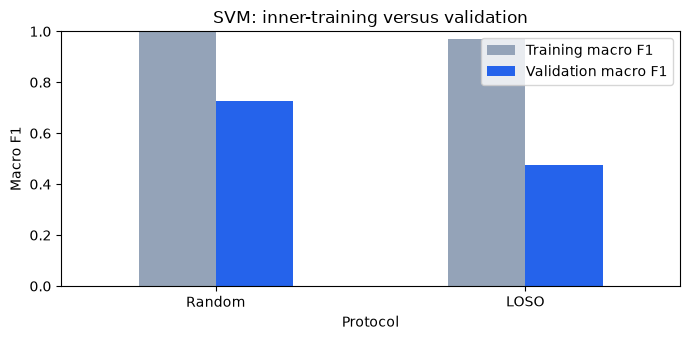

In [20]:
svm_C = [0.01,0.05,0.1,0.5,1,5,10,50,100,1000]
svm_gamma = ['scale',0.00001,0.0001,0.0005,0.001,0.005,0.01]
svm_grid = [
    {'model__kernel':['rbf'], 'model__C':svm_C, 'model__gamma':svm_gamma},
    {'model__kernel':['linear'], 'model__C':svm_C}
]
svm_validation = tune_classical('SVM', SVC(), svm_grid)

### 9.7 MLP optimisation — PyTorch and balanced randomised search

Baseline and tuning use the **same PyTorch MLP class**, defined in section 7,
with shared automatic CUDA/CPU selection, a 1500-iteration upper limit and the
same training-loss stopping rule. The fixed baseline uses `(100,)`, ReLU, Adam,
alpha 0.0001 and LR 0.001. Tuning searches the settings below through the same
`Pipeline(StandardScaler, model)` interface and explicit inner folds. No extra
wrapper package is needed. GPU fitting does not guarantee higher accuracy or
faster execution on this small dataset. Prediction stays on CPU.

| Setting | Search space |
| --- | --- |
| Hidden layers | `(64,)`, `(128,)`, `(64,32)`, `(128,64)` |
| Activation | ReLU, tanh |
| Solver | Adam, full-batch L-BFGS |
| L2 alpha | 0.0001, 0.001, 0.01, 0.1, 1.0 |
| Adam learning rate | 0.0003, 0.001 |
| Training limit | 1500 Adam epochs or total L-BFGS iterations |

The full space has 120 configurations (80 Adam and 40 L-BFGS). Sample **three Adam and three L-BFGS
configurations per architecture**, giving **24 total candidates**:
12 Adam + 12 L-BFGS. The `(100,)` baseline is evaluated separately and is
not a tuning candidate. No extra reference candidate is added. All sampled
configurations and the baseline use up to 1500 iterations.

Sample each solver branch without replacement using seeds 42 and 43 respectively;
reuse the same list across all outer folds. Both solvers and all four architectures
are guaranteed coverage; other parameter values are not. Configure the per-solver
budget with `MLP_SAMPLES_PER_SOLVER=3` (six candidates per architecture). The common GridSearchCV
runner evaluates singleton grids for these 24 candidates, rather than the full
120-configuration space. L-BFGS does not search Adam's learning rate; its
line-search step starts at 1.0. The settings table reports sampled solver counts.

Define training loss explicitly as **mean cross-entropy + alpha/(2 × N_train)
× sum of squared weight matrices**, excluding biases. Adam weight_decay stays
zero. This is a documented, sklearn-inspired objective, not a claim of exact
sklearn minibatch equivalence. Adam uses shuffled batches of min(200, N_train)
and stops after ten epochs without a training-loss improvement of 0.0001.
No internal validation holdout or validation-based stopping is used. L-BFGS uses
one full-batch closure-based solve, strong-Wolfe line search, gradient tolerance
0.0001, change tolerance 1e-9, and a 15000 function-evaluation budget. Budget
warnings remain visible. Both solvers initialise fresh weights on every fit.

Use **one MLP fitting job**, even if TUNING_JOBS is increased for classical
models. Every inner training fold fits its own scaler; validation macro F1
selects the candidate. Refit fresh on all outer training clips with the selected
settings and training-only stopping rule. No outer test data enter selection.
Models are stored on CPU after fitting to avoid accumulating GPU allocations.

In [ ]:
from sklearn.model_selection import ParameterSampler

# The estimator, MLP_MAX_ITER and MLP_DEVICE are shared with section 7.
MLP_ARCHITECTURES = [(64,), (128,), (64, 32), (128, 64)]
MLP_SAMPLES_PER_SOLVER = 3               # Per architecture: 3 Adam + 3 L-BFGS; 24 total

def sample_mlp_candidates(samples_per_solver=MLP_SAMPLES_PER_SOLVER, seed=TUNING_SEED):
    """Sample each solver separately so every architecture covers Adam and L-BFGS."""
    if not 1 <= samples_per_solver <= 10:
        raise ValueError('Use 1–10 samples per solver; L-BFGS has 10 distinct settings per architecture.')
    candidates = []
    for architecture in MLP_ARCHITECTURES:
        common = {'model__hidden_layer_sizes':[architecture], 'model__activation':['relu', 'tanh'],
                  'model__alpha':[0.0001, 0.001, 0.01, 0.1, 1.0], 'model__max_iter':[MLP_MAX_ITER]}
        adam_space = {**common, 'model__solver':['adam'],
                      'model__learning_rate_init':[0.0003, 0.001]}
        lbfgs_space = {**common, 'model__solver':['lbfgs']}  # No irrelevant Adam learning rate
        candidates.extend(ParameterSampler(adam_space, n_iter=samples_per_solver, random_state=seed))
        candidates.extend(ParameterSampler(lbfgs_space, n_iter=samples_per_solver, random_state=seed+1))
    return [{key:[value] for key, value in params.items()} for params in candidates]

mlp_sampled_grid = sample_mlp_candidates()
mlp_sampled_params = list(ParameterGrid(mlp_sampled_grid))
display(pd.DataFrame([{
    'Implementation':'PyTorch MLP', 'Search':'Balanced random sampling (ParameterSampler)',
    'Sampled candidates':len(mlp_sampled_grid),
    'Samples per solver per architecture':MLP_SAMPLES_PER_SOLVER,
    'Candidates per architecture':2*MLP_SAMPLES_PER_SOLVER,
    'Sampled Adam':sum(p['model__solver']=='adam' for p in mlp_sampled_params),
    'Sampled L-BFGS':sum(p['model__solver']=='lbfgs' for p in mlp_sampled_params),
    'Training device':str(torch.device('cuda' if torch.cuda.is_available() else 'cpu')) if MLP_DEVICE == 'auto' else MLP_DEVICE,
    'Parallel jobs':1, 'Early stopping':'Training loss only; no internal validation split'
}]))
mlp_validation = tune_classical('MLP', TorchMLPClassifier(max_iter=MLP_MAX_ITER, random_state=TUNING_SEED, device=MLP_DEVICE),
    mlp_sampled_grid, search_method=f'Balanced architecture/solver random sampling: {len(mlp_sampled_grid)} candidates', n_jobs=1)

### 9.8 CNN optimisation

Compare two configurations with **2 or 3 convolutions**. The section 7 baseline
uses 16/32 convolution channels and Dense 64. Every network uses BatchNorm and
ReLU after each convolution, max pooling after only the first two convolutions,
4×4 adaptive pooling, a hidden dense layer, ReLU, Dropout 0.4 and five output
logits. Shared training settings, inner folds and helper functions come from
section 7. Basic/rich inputs and outer test folds remain fixed.

| Stage | Convolution channels | Hidden dense units | Initial learning rate |
| --- | --- | ---: | ---: |
| Baseline (section 7) | 16 → 32 | 64 | 0.001 |
| Optimisation candidate 1 | 32 → 64 | 128 | 0.001 |
| Optimisation candidate 2 | 32 → 64 → 128 | 256 | 0.001 |

This gives **two candidates per outer split**. The baseline is evaluated
separately and is not a tuning candidate. Remove the four-layer CNN and initial
learning-rate search. Both candidates start at Adam's default LR **0.001**;
the existing validation-based LR scheduler can still reduce it during training.
Convolution depth/width and dense-layer size change together, so this comparison
does not isolate the effect of depth alone. All use weight decay 0.0001, batch
size 32, a **50-epoch maximum**, and identical checkpoint, stopping and LR
scheduling rules. Actual epochs/checkpoints can differ by fold/configuration.

Checkpoint on lowest inner-validation loss with improvement threshold 0.0001.
Reduce LR by half with patience 5 to a minimum 1e-5. Stop after 15 non-improving
epochs once at least 20 have run. Earlier checkpoints/refit epochs are allowed.
Evaluate the restored inner checkpoints and select by mean validation macro F1.
Refit fresh weights on all outer training clips for the rounded-up median inner
best epoch and median inner LR schedule. No outer test data control selection.

The predefined baseline also uses this validation-calibrated training procedure
but does not search architecture/LR. Training/validation curves remain diagnostics, not test results.

In [ ]:
cnn_candidates = [
    {**CNN_BASELINE_CONFIG, 'name':'Two-layer CNN (32/64, Dense 128)',
     'architecture':'two_layer', 'hidden_dense':128},
    {**CNN_BASELINE_CONFIG, 'name':'Three-layer CNN (32/64/128, Dense 256)',
     'architecture':'three_layer', 'hidden_dense':256}
]
display(pd.DataFrame(cnn_candidates))

selected_settings[:] = [row for row in selected_settings if row['Model'] != 'CNN']
cnn_history_parts, cnn_search_rows = [], []
for fold in tuning_folds:
    display(Markdown(f"**CNN: {fold['name']}** — inner validation then outer-training refit"))
    candidate_rows, candidate_histories = [], []
    for candidate_id, config in enumerate(cnn_candidates):
        scores, accuracies, training_scores, best_epochs, histories = [], [], [], [], []
        for inner_id, (train_idx, valid_idx) in enumerate(fold['inner'], start=1):
            train_global, valid_global = fold['train'][train_idx], fold['train'][valid_idx]
            image_mean, image_std = cnn_normalisation(Z[train_global])
            model, history, best_epoch = fit_cnn(
                (Z[train_global]-image_mean)/image_std, y[train_global], config, CNN_MAX_EPOCHS,
                (Z[valid_global]-image_mean)/image_std, y[valid_global], seed=TUNING_SEED+inner_id)
            best_row = history.loc[history.Epoch==best_epoch].iloc[0]
            scores.append(best_row['Validation macro F1'])
            accuracies.append(best_row['Validation accuracy'])
            training_scores.append(best_row['Training macro F1'])
            best_epochs.append(best_epoch)
            history['Outer split'], history['Protocol'] = fold['name'], fold['setting']
            history['Candidate'], history['Inner fold'] = config['name'], inner_id
            histories.append(history)
            cnn_history_parts.append(history)
            del model
        candidate_histories.append(histories)
        candidate_rows.append({'Outer split':fold['name'], 'Protocol':fold['setting'],
            'Candidate':config['name'], 'Candidate index':candidate_id,
            'Validation macro F1':float(np.mean(scores)), 'Validation F1 std':float(np.std(scores)),
            'Validation accuracy':float(np.mean(accuracies)), 'Training macro F1':float(np.mean(training_scores)),
            'Train-validation F1 gap':float(np.mean(training_scores)-np.mean(scores)),
            'Refit epochs':int(np.ceil(np.median(best_epochs))), 'Inner best epochs':str(best_epochs),
            'Checkpoint rule':'Lowest inner-validation loss', 'Settings':json.dumps(config)})
    best = max(candidate_rows, key=lambda row:row['Validation macro F1'])
    for row in candidate_rows:
        row['Selected'] = row['Candidate index']==best['Candidate index']
        cnn_search_rows.append(row)
    selected_config = cnn_candidates[best['Candidate index']]
    learning_rates = refit_learning_rates(candidate_histories[best['Candidate index']], best['Refit epochs'])
    image_mean, image_std = cnn_normalisation(Z[fold['train']])
    final_cnn, _, _ = fit_cnn((Z[fold['train']]-image_mean)/image_std,
                      y[fold['train']], selected_config, best['Refit epochs'],
                      learning_rate_schedule=learning_rates)
    optimised_models[fold['name']]['CNN'] = {'model':final_cnn.cpu(),
        'image_mean':image_mean, 'image_std':image_std, 'config':selected_config.copy(),
        'epochs':best['Refit epochs'], 'learning_rate_schedule':learning_rates}
    selected_settings.append({'Model':'CNN', 'Outer split':fold['name'], 'Protocol':fold['setting'],
        'Feature set':FEATURE_SET, 'CNN input':CNN_INPUT_NAME,
        'Selected settings':json.dumps(selected_config), 'Validation macro F1':best['Validation macro F1'],
        'Validation accuracy':best['Validation accuracy'], 'Training macro F1':best['Training macro F1'],
        'Train-validation F1 gap':best['Train-validation F1 gap'], 'Inner folds':len(fold['inner']),
        'Refit epochs':best['Refit epochs'], 'Final refit learning rate':learning_rates[-1]})
    display(pd.DataFrame(candidate_rows).drop(columns='Candidate index').round(4))
cnn_history = pd.concat(cnn_history_parts, ignore_index=True)
validation_results['CNN'] = pd.DataFrame(cnn_search_rows)
show_candidate_rankings('CNN', validation_results['CNN'])

In [ ]:
selection_summary = pd.DataFrame(selected_settings)
display(Markdown('**Selected settings for all models and outer splits**'))
display(selection_summary.round(4))

for setting in ['Random','LOSO']:
    example_outer_fold = next(fold['name'] for fold in tuning_folds if fold['setting']==setting)
    choices = validation_results['CNN']
    choice = choices[(choices['Outer split']==example_outer_fold) & choices.Selected].iloc[0]
    curve = cnn_history[(cnn_history['Outer split']==example_outer_fold) &
                        (cnn_history.Candidate==choice['Candidate']) & (cnn_history['Inner fold']==1)]
    checkpoint_epoch = int(curve.loc[curve['Selected checkpoint'], 'Epoch'].iloc[0])
    fig, axes = plt.subplots(1,3,figsize=(15,3.5))
    axes[0].plot(curve.Epoch,curve['Training loss'],label='Training')
    axes[0].plot(curve.Epoch,curve['Validation loss'],label='Validation')
    axes[0].set(title='Evaluation-mode loss',xlabel='Epoch',ylabel='Cross-entropy loss')
    axes[0].axvline(checkpoint_epoch,color='#64748b',linestyle='--',label='Selected checkpoint')
    axes[0].legend()
    axes[1].plot(curve.Epoch,curve['Training macro F1'],label='Training')
    axes[1].plot(curve.Epoch,curve['Validation macro F1'],label='Validation')
    axes[1].set(title='Macro F1',xlabel='Epoch',ylabel='Macro F1',ylim=(0,1))
    axes[1].axvline(checkpoint_epoch,color='#64748b',linestyle='--')
    axes[1].legend()
    axes[2].step(curve.Epoch,curve['Learning rate'],where='post',color='#0d9488')
    axes[2].set(title='Learning rate',xlabel='Epoch',ylabel='Adam LR',yscale='log')
    fig.suptitle(f"{example_outer_fold}: {choice['Candidate']}, inner fold 1")
    fig.tight_layout()
    plt.show()

## 10. Final model prediction and evaluation

After all tuning is complete, predict the same outer test recordings used by the
baseline. Scikit-learn pipelines accept **raw** X and apply their fitted training
scaler; CNN bundles apply normalisation fitted on all outer training images.
DummyClassifier is reused unchanged. Optimised configurations can differ by outer
fold because each selection used only that fold's training data.

Report pooled out-of-fold accuracy and macro F1 for both protocols. Each
recording contributes once per protocol per stage. Also show the unweighted fold
mean ± sample standard deviation: five random scores and six LOSO scores.
The comparison tables include both stages. Accuracy changes are percentage points;
macro F1 changes are score differences. Negative changes are retained: tuning does
not guarantee improvement. The speaker-level table shows LOSO variation. Use inner
validation, not these outer-test results, to select settings for further experiments.

All classical pipelines use every feature in the selected basic/rich preset;
the input representation and outer test recordings remain fixed across stages.
Speaker-level tables report both accuracy and macro F1. Training/validation
diagnostics explain gaps but never choose an outer-test winner. Further designs
made after inspecting outer results remain exploratory until independently confirmed.

MLP compares a **fixed-configuration PyTorch baseline** against the tuned
**same PyTorch implementation**. Both share features, scaling rules, outer folds,
the 1500-iteration upper limit and training-loss stopping.

In [ ]:
if (FEATURE_SET != baseline_feature_set or X.shape[1] != baseline_feature_count
        or tuple(Z.shape[1:]) != baseline_cnn_shape):
    raise RuntimeError('Feature preset changed: re-run sections 4–9 before final evaluation.')
missing = [(fold['name'],name) for fold in tuning_folds for name in model_order
           if name not in optimised_models[fold['name']]]
if missing:
    raise RuntimeError(f'Run every tuning subsection first. Missing models: {missing}')
baseline_lookup = {(record['Fold'],record['Model']):record for record in baseline_prediction_records}
optimised_predictions,optimised_prediction_records,speaker_rows = [],[],[]
for fold in tuning_folds:
    test = fold['test']
    for name in model_order:
        fitted = optimised_models[fold['name']][name]
        if name=='CNN':
            model = fitted['model'].to(DEVICE)
            predicted = cnn_predict(model,(Z[test]-fitted['image_mean'])/fitted['image_std'])
            model.cpu()
        else:
            predicted = fitted.predict(X[test])
        actual = y[test]
        optimised_predictions.append((fold['setting'],name,actual.copy(),predicted.copy()))
        optimised_prediction_records.append({'Protocol':fold['setting'],'Fold':fold['name'],'Model':name,
            'Indices':test.copy(),'Actual':actual.copy(),'Predicted':predicted.copy()})
        baseline_record = baseline_lookup[(fold['name'],name)]
        np.testing.assert_array_equal(baseline_record['Indices'],test)
        np.testing.assert_array_equal(baseline_record['Actual'],actual)
        if fold['setting']=='LOSO':
            for stage,values in [('Baseline',baseline_record['Predicted']),('Optimised',predicted)]:
                speaker_rows.append({'Model':name,'Stage':stage,'Speaker':metadata.speaker.iloc[test].iloc[0],
                    'Accuracy':accuracy_score(actual,values),
                    'Macro F1':f1_score(actual,values,average='macro',labels=labels,zero_division=0)})
optimised_summary,optimised_fold_scores,optimised_fold_summary = summarise_predictions(optimised_prediction_records)
final_summary = pd.concat({'Baseline':baseline_summary,'Optimised':optimised_summary},names=['Stage','Model'])
final_summary = final_summary.reorder_levels(['Model','Stage']).reindex(
    pd.MultiIndex.from_product([model_order,['Baseline','Optimised']],names=['Model','Stage']))
display(Markdown('**MLP implementation:** baseline and optimised models use the same PyTorch class. '
    'The fixed baseline uses (100,), ReLU and Adam; both stages share a 1500-iteration upper limit.'))
display(final_summary.style.format(metric_format).set_caption(
    f'Pooled out-of-fold final comparison — {FEATURE_SET}, {X.shape[1]} acoustic features; CNN {CNN_INPUT_NAME}'))
final_fold_summary = pd.concat({'Baseline':baseline_fold_summary,'Optimised':optimised_fold_summary},
                               names=['Stage','Model','Protocol']).reorder_levels(['Model','Stage','Protocol'])
final_fold_summary = final_fold_summary.reindex(pd.MultiIndex.from_product(
    [model_order,['Baseline','Optimised'],['Random','LOSO']],names=['Model','Stage','Protocol']))
show_fold_statistics(final_fold_summary,'Baseline versus optimised fold mean and standard deviation')
final_fold_scores = pd.concat([baseline_fold_scores.assign(Stage='Baseline'),
                              optimised_fold_scores.assign(Stage='Optimised')],ignore_index=True)
improvement = optimised_summary-baseline_summary
improvement = improvement.rename(columns={'Random accuracy':'Random accuracy change (pp)',
    'Random macro F1':'Random macro F1 change', 'LOSO accuracy':'LOSO accuracy change (pp)',
    'LOSO macro F1':'LOSO macro F1 change'})
for column in ['Random accuracy change (pp)','LOSO accuracy change (pp)']:
    improvement[column] *= 100
display(improvement.style.format('{:+.3f}').set_caption('Optimised minus baseline'))
speaker_results = pd.DataFrame(speaker_rows)
display(speaker_results.pivot(index=['Model','Stage'],columns='Speaker',values='Accuracy')
        .style.format('{:.1%}').set_caption('LOSO accuracy for each held-out speaker'))
display(speaker_results.pivot(index=['Model','Stage'],columns='Speaker',values='Macro F1')
        .style.format('{:.3f}').set_caption('LOSO macro F1 for each held-out speaker'))

In [ ]:
fig, axes = plt.subplots(2,2,figsize=(13,9),sharex='col')
for row, setting in enumerate(['Random','LOSO']):
    for column, metric in enumerate(['accuracy','macro F1']):
        key = f'{setting} {metric}'
        plot_values = pd.DataFrame({'Baseline':baseline_summary[key],
                                    'Optimised':optimised_summary[key]}).reindex(model_order)
        plot_values.plot.barh(ax=axes[row,column],color=['#94a3b8','#2563eb'])
        axes[row,column].set(title=f"{'Random 5-fold CV (pooled)' if setting=='Random' else 'LOSO (pooled)'}: {metric}",
                            xlabel=metric,ylabel='',xlim=(0,1))
        axes[row,column].invert_yaxis()
        axes[row,column].grid(axis='x',alpha=0.2)
        axes[row,column].set_axisbelow(True)
        if metric=='accuracy':
            axes[row,column].xaxis.set_major_formatter(PercentFormatter(1))
fig.suptitle('Baseline versus optimised models: pooled out-of-fold test predictions')
fig.tight_layout()
plt.show()